# Pathological Search Suite — Organized by Domain Family

Declaratively composed via `ceac_bench.reporting`, this notebook organizes every multi-step lock, signalling pathway, and K562 genetic interaction benchmark **strictly by domain family**, pairing each single-stage screen directly with its **multi-step path-dependent counterpart** (where both Russo–Van Roy policy-tree IDS `ids_action_tree` and quotiented on-path IDS `ids_action_onpath` break across $k = 0 \to 3$ while periwinkle `ceac_ranked` stays flat):

1. **Part I — Combination Lock Family (`combination_lock` & `bidirectional_lock`, $L \in \{1, 2, 3, 4\}$)**
2. **Part II — Signalling Pathway Family (`epistatic_signalling` $\to$ Path-Dependent `signalling_rewiring`, $H = 3$)**
3. **Part III — Human K562 Genetic Interaction Family (`gi_arrayed` / `gi_multiplexed` $\to$ Path-Dependent `canalized_gi`, $H = 3$)**
4. **Part IV — Consolidated `StudyBundle` Summary Tables & Unified CLI Entrypoints**


In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "ceac_bench").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

from ceac_pathologies.report import (
    draw_architecture,
    draw_epistasis_discovery_traces,
    draw_epistasis_overlaid_performance,
    draw_locks_overlaid_performance,
    draw_response,
    load_export,
)
from ceac_ranked.study import (
    draw_gi_discovery_traces,
    draw_gi_overlaid_performance,
    draw_gi_ranked_mechanisms,
    draw_gi_ranked_response,
    load_gi_ranked_export,
)
from ceac_pathdep.study import draw_pathdep_architecture, draw_pathdep_discovery_traces, load_pathdep_export
from ceac_critic_diagnostics import draw_suite_critic_traces, load_suite_critic_audit
from ceac_critic_diagnostics.run_pathologies_audit import SUITE_SPECS
from ceac_bench.reporting import (
    DoseTransitionMarkdownTable,
    PairedAdvantageMarkdownTable,
    SingleEnvCriticBellmanPlot,
    SingleEnvDoseScalingPlot,
    SingleEnvTimeTracePlot,
)
from ceac_bench.store import LegacyBundleAdapter

locks = load_export(ROOT / "notebooks/evidence/pathologies_locks")
epistasis = load_export(ROOT / "notebooks/evidence/pathologies_epistasis")
gi_ranked = load_gi_ranked_export(ROOT / "notebooks/evidence/pathologies_gi_ranked")
pathdep_raw = load_pathdep_export(ROOT / "notebooks/evidence/pathologies_pathdep")
bio_pathdep_bundle = LegacyBundleAdapter.load_bio_pathdep(ROOT / "notebooks/evidence/pathologies_pathdep")

locks_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_locks")
epistasis_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_epistasis")
gi_critic = load_suite_critic_audit(ROOT / "notebooks/evidence/pathologies_gi_ranked")

print(
    f"Verified portable exports via ceac_bench: {len(locks['runs'])} lock cells, "
    f"{len(epistasis['runs'])} epistasis cells, {len(gi_ranked['sweep_rows'])} K562 GI cells, and "
    f"{len(bio_pathdep_bundle.cells)} path-dependent StudyBundle v2 cells. No training launched."
)


Verified portable exports via ceac_bench: 192 lock cells, 108 epistasis cells, 288 K562 GI cells, and 288 path-dependent StudyBundle v2 cells. No training launched.


---
## Part I — Combination Lock Family (`combination_lock` & `bidirectional_lock`, $L \in \{1, 2, 3, 4\}$)


### 1.1 Gated Lock Depth Scaling, Overlaid Regret & Held-Out Critic Bellman Error


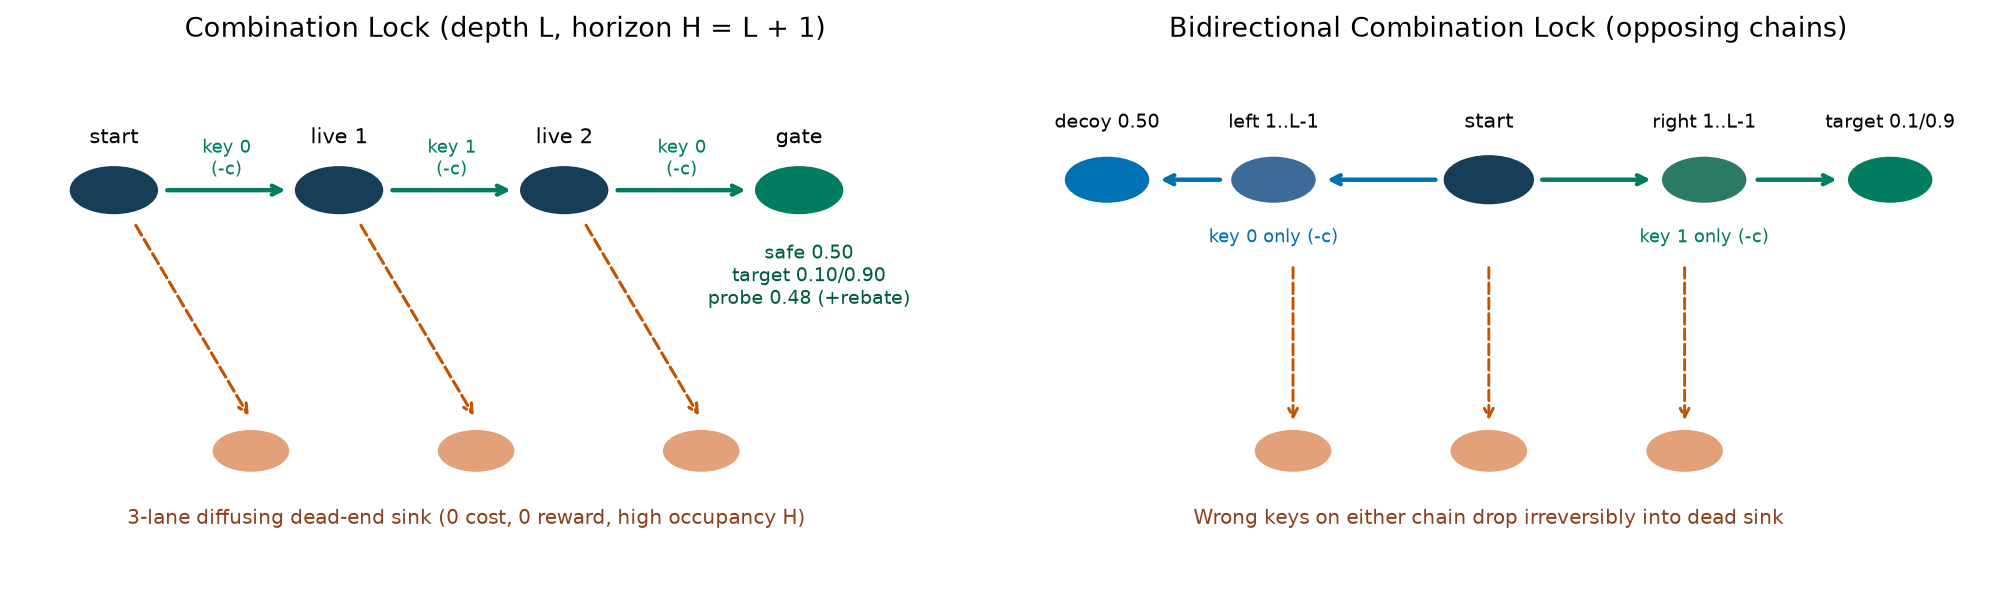

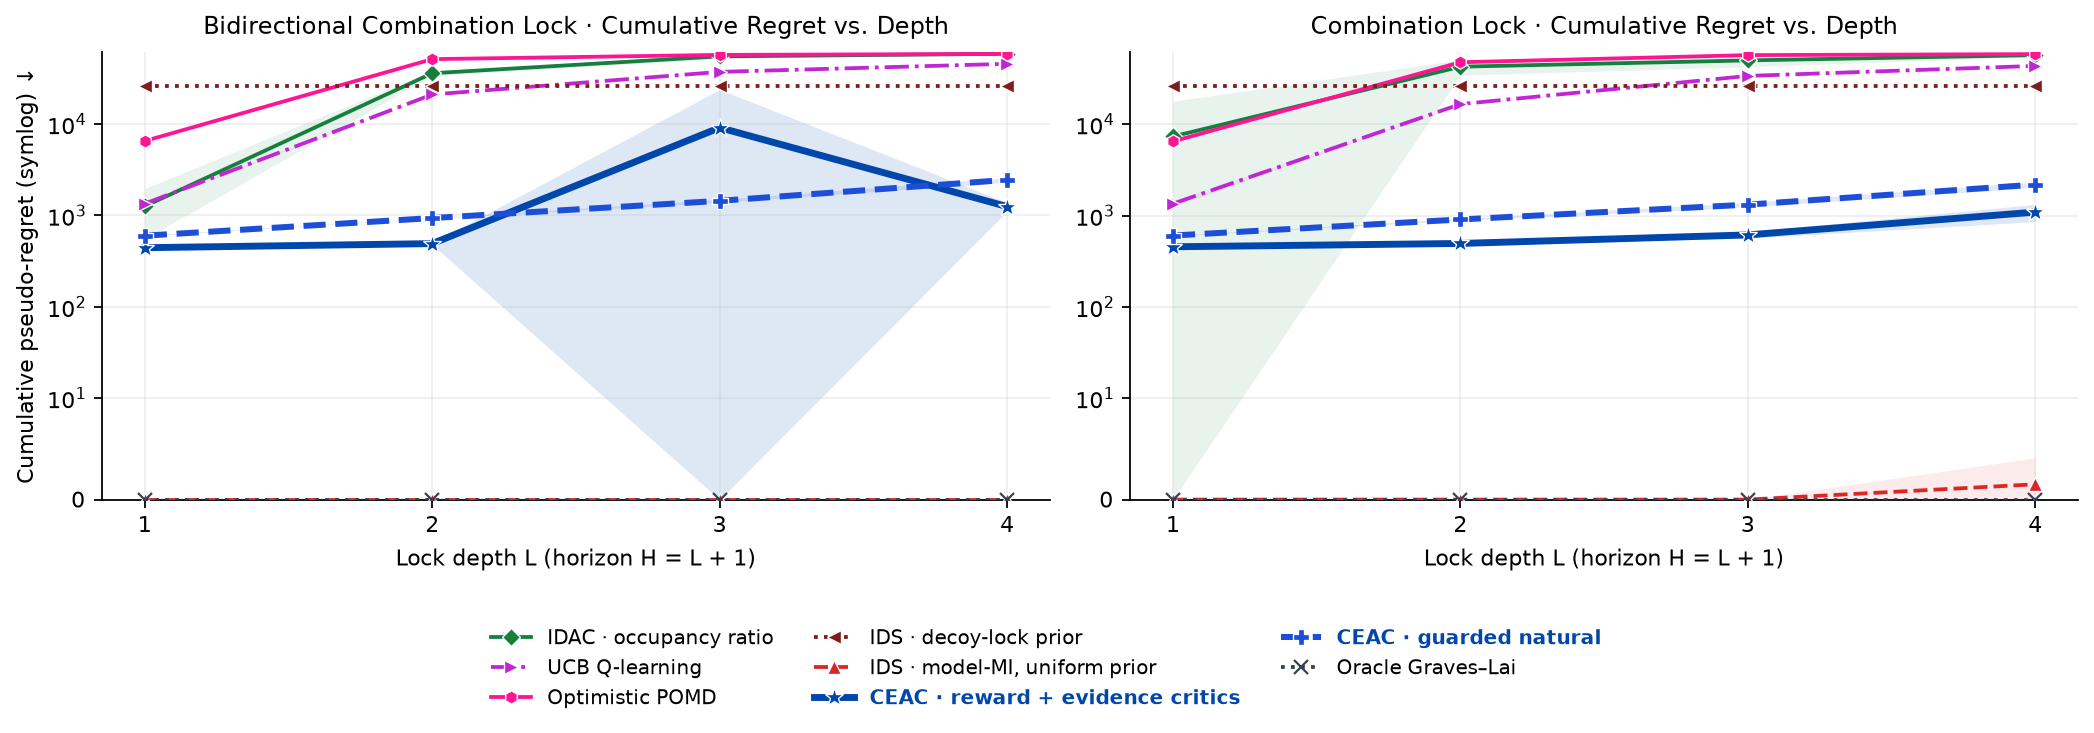

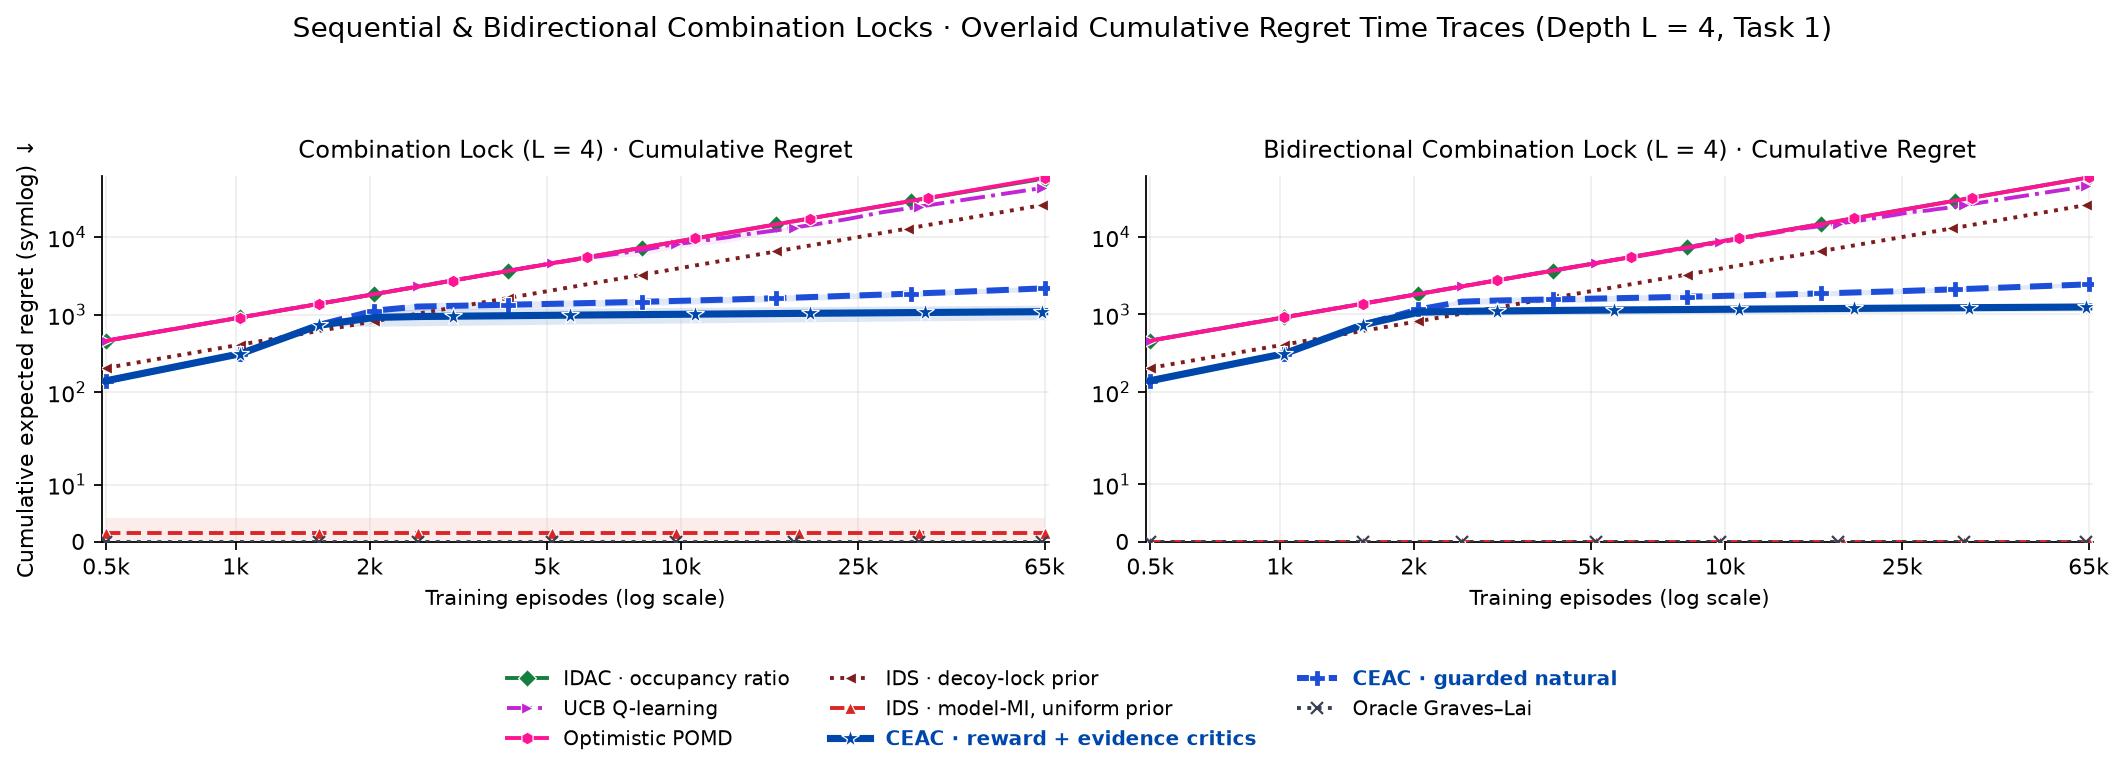

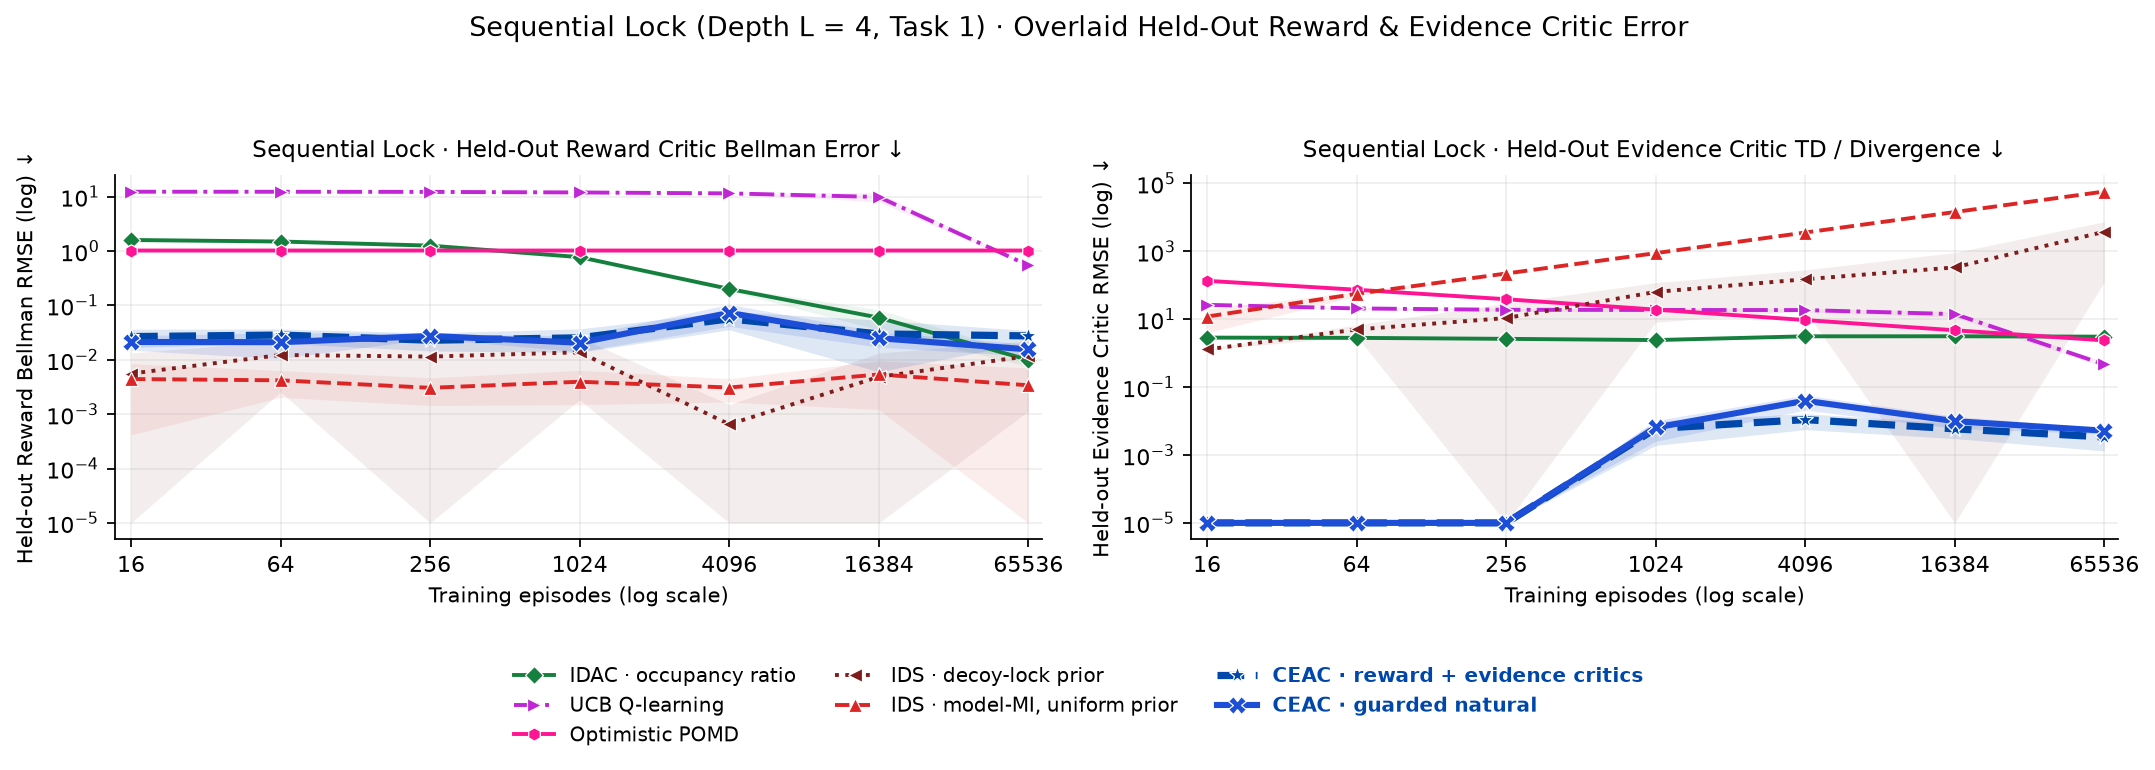

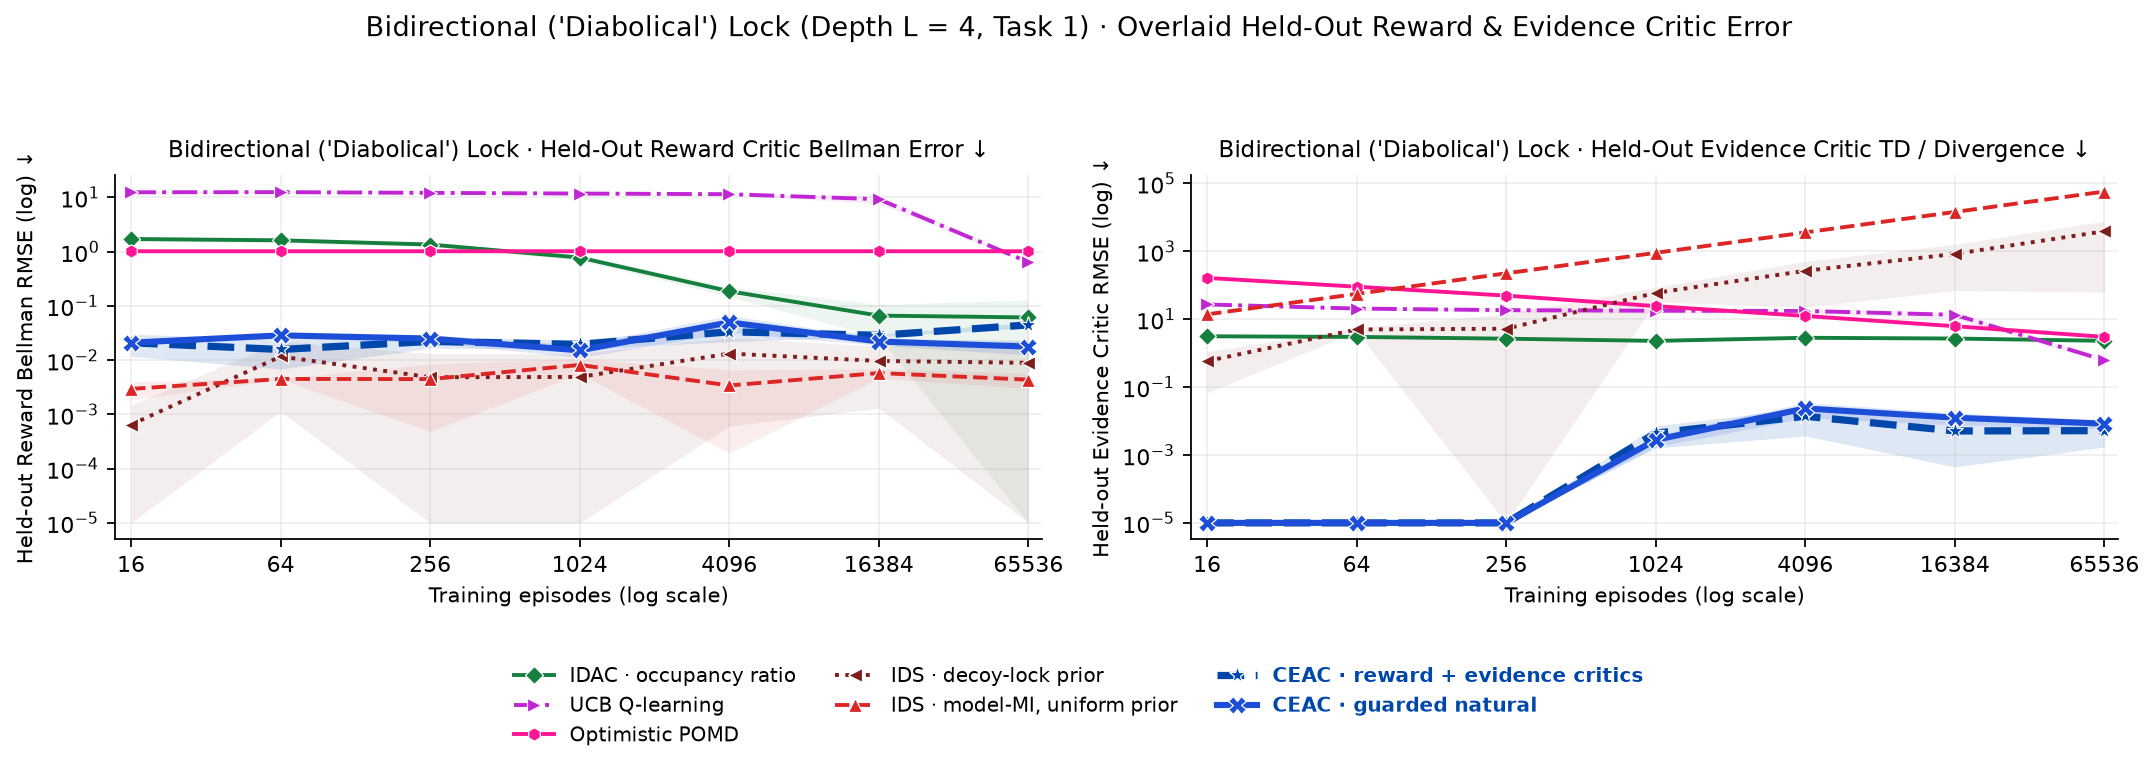

In [2]:
fig = draw_architecture("locks")
plt.show()
fig = draw_response(locks)
plt.show()
fig = draw_locks_overlaid_performance(locks, dose=4, task=1, metric="cumulative_regret")
plt.show()
spec_locks = SUITE_SPECS["locks"]
for k_key, k_title in spec_locks["kinds"]:
    fig = draw_suite_critic_traces(
        locks_critic["cells"],
        [(k_key, k_title)],
        target_dose=spec_locks["target_dose"],
        suptitle=f"{k_title} (Depth L = 4, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
        method_order=spec_locks["methods"],
    )
    plt.show()


---
## Part II — Signalling Pathway Family (`epistatic_signalling` $\to$ `signalling_rewiring`)


### 2.1 Single-Stage Epistatic Signalling under Off-Pathway Pleiotropy (`epistatic_signalling`)


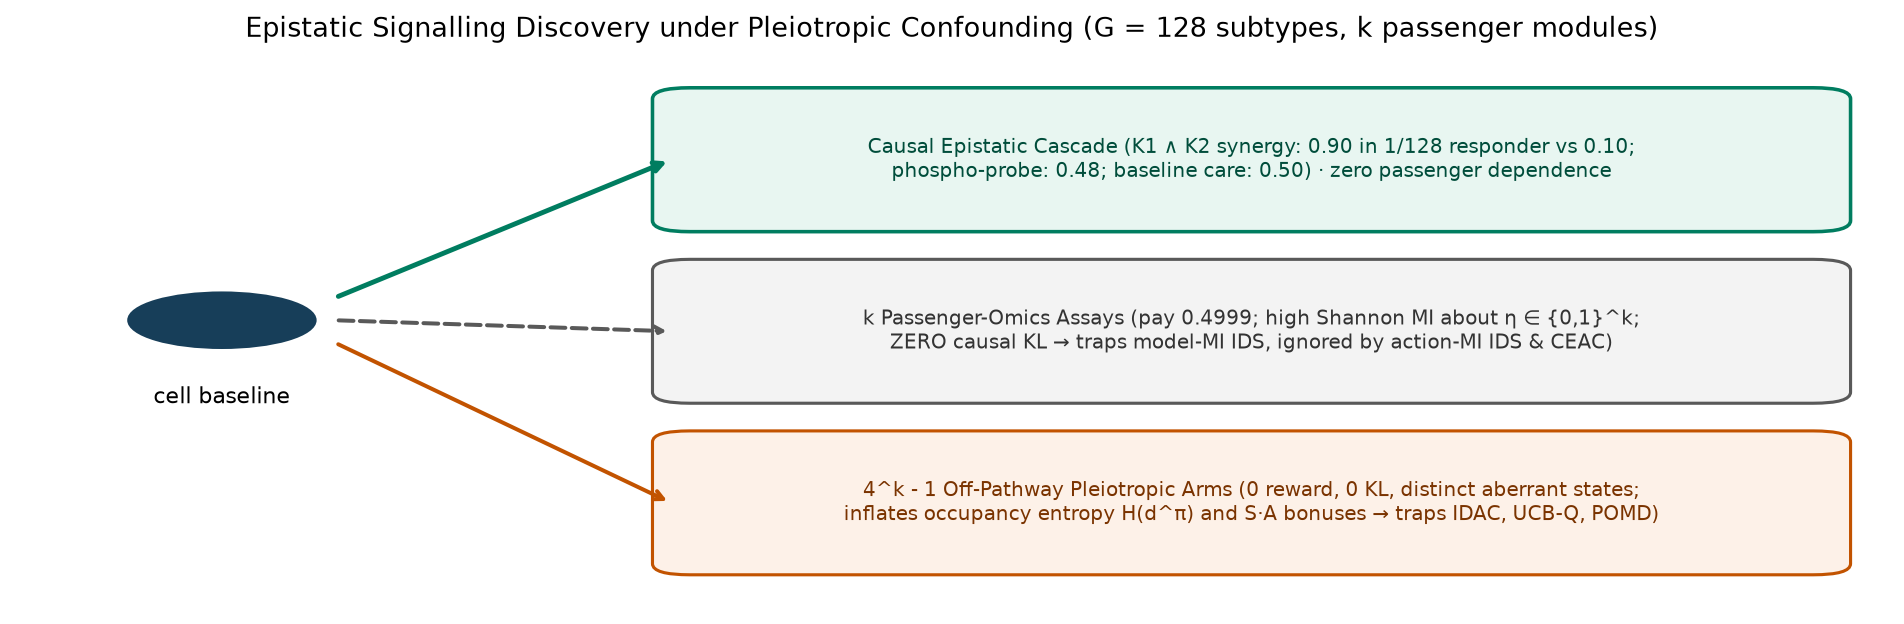

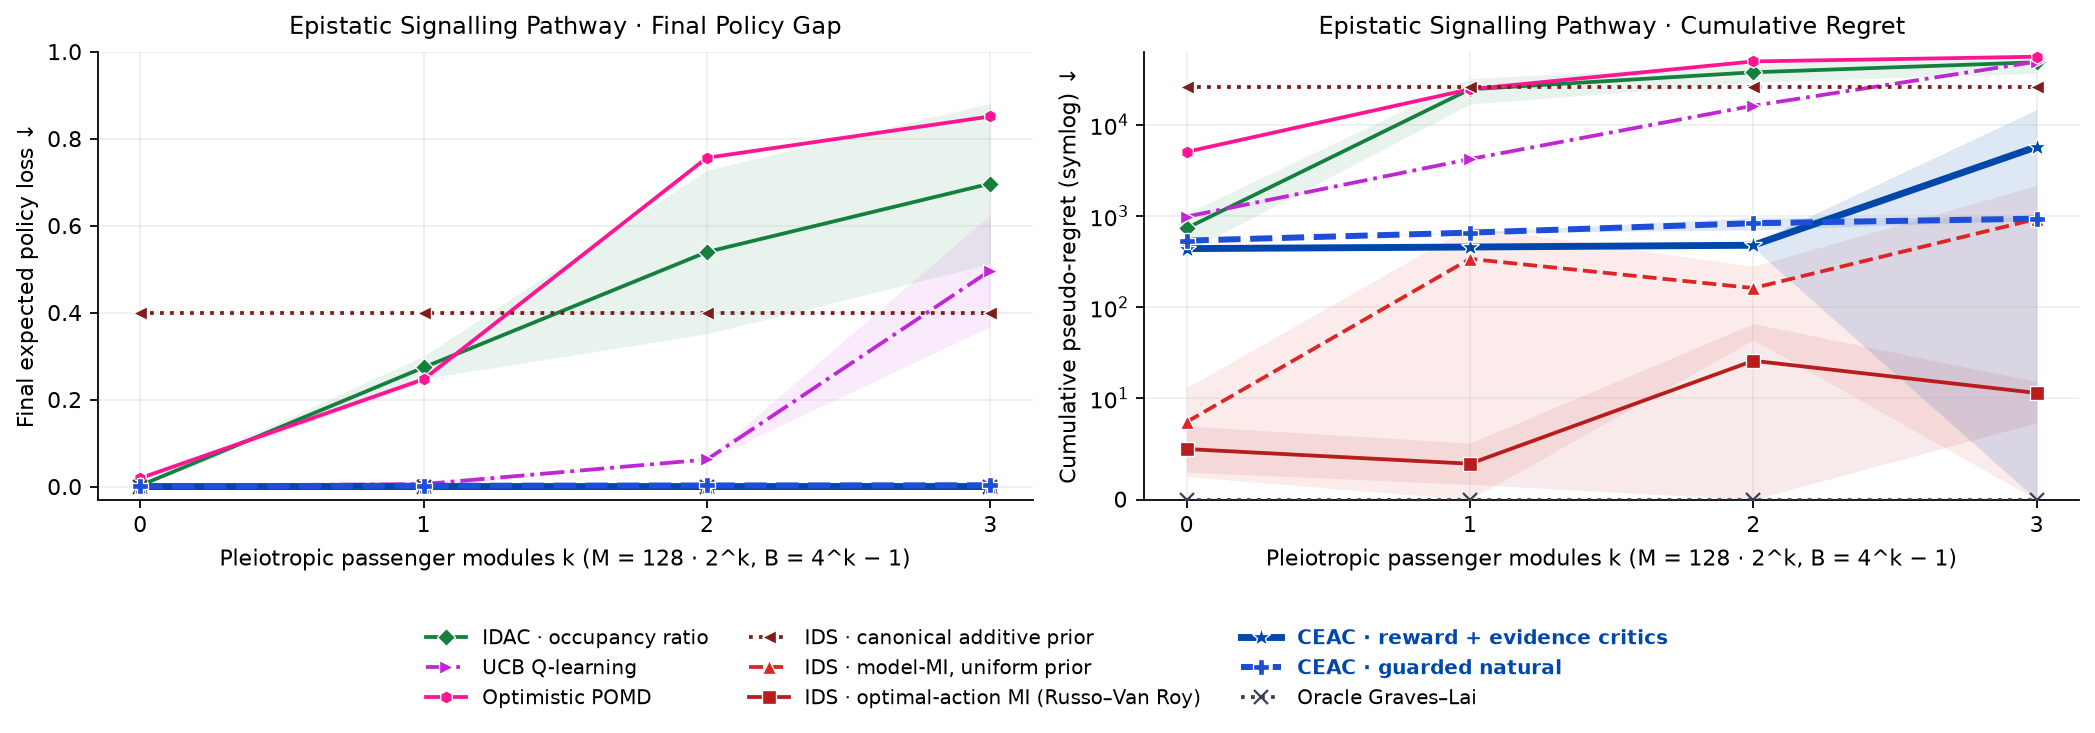

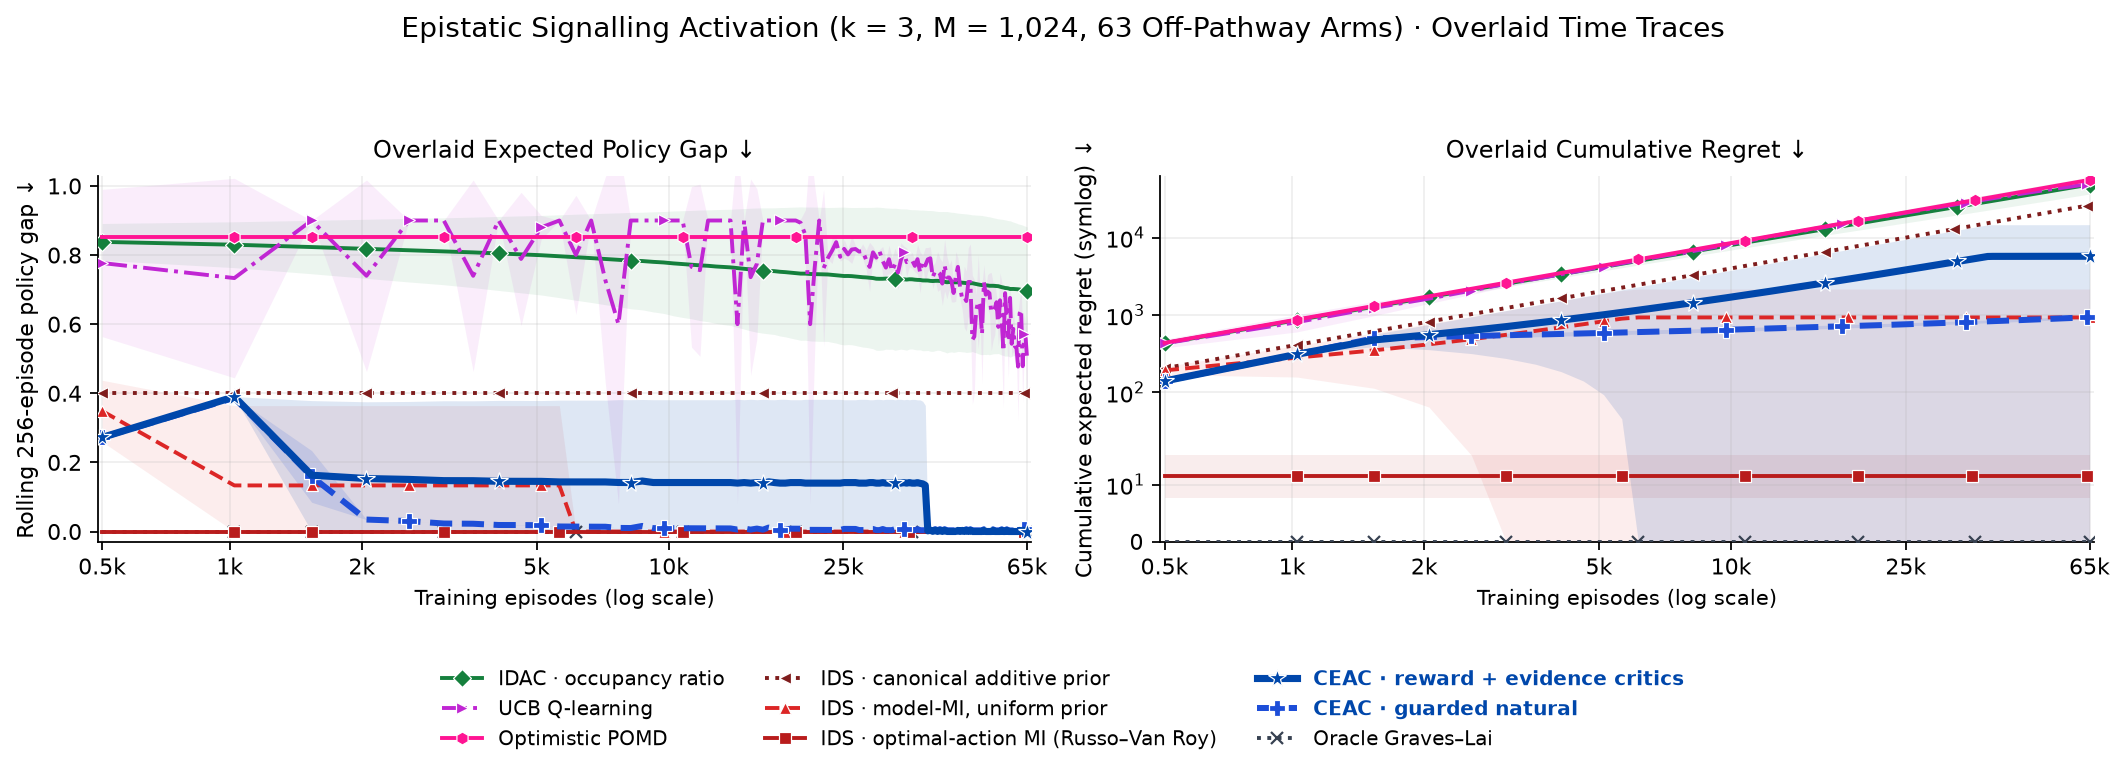

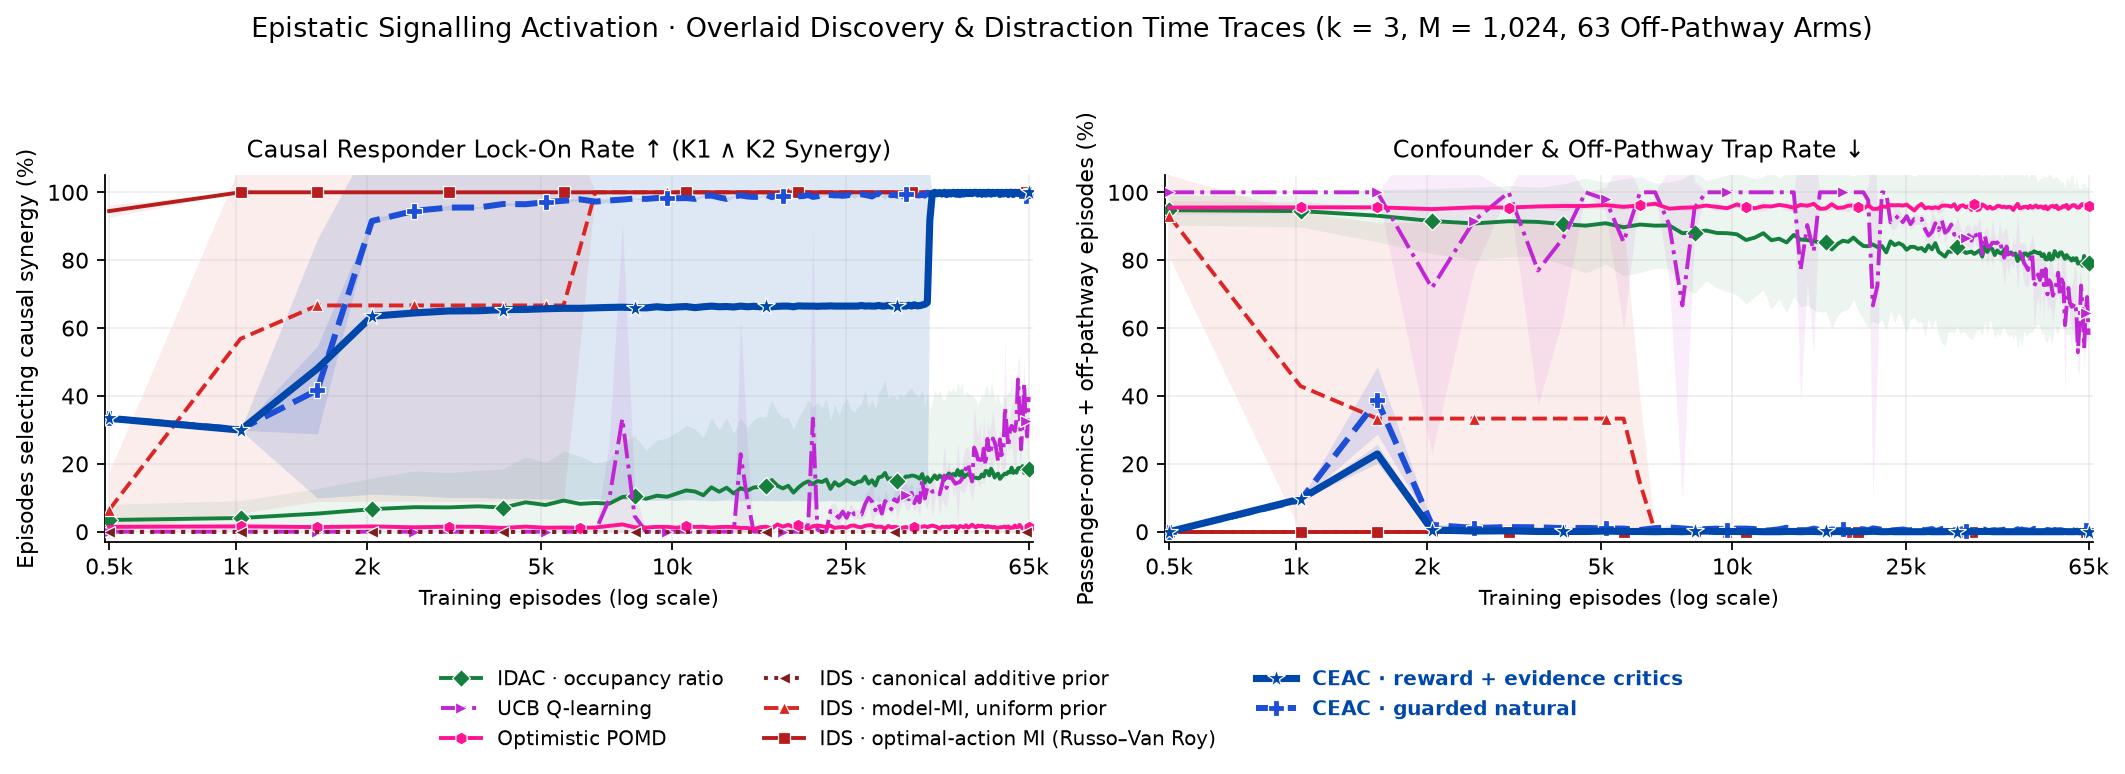

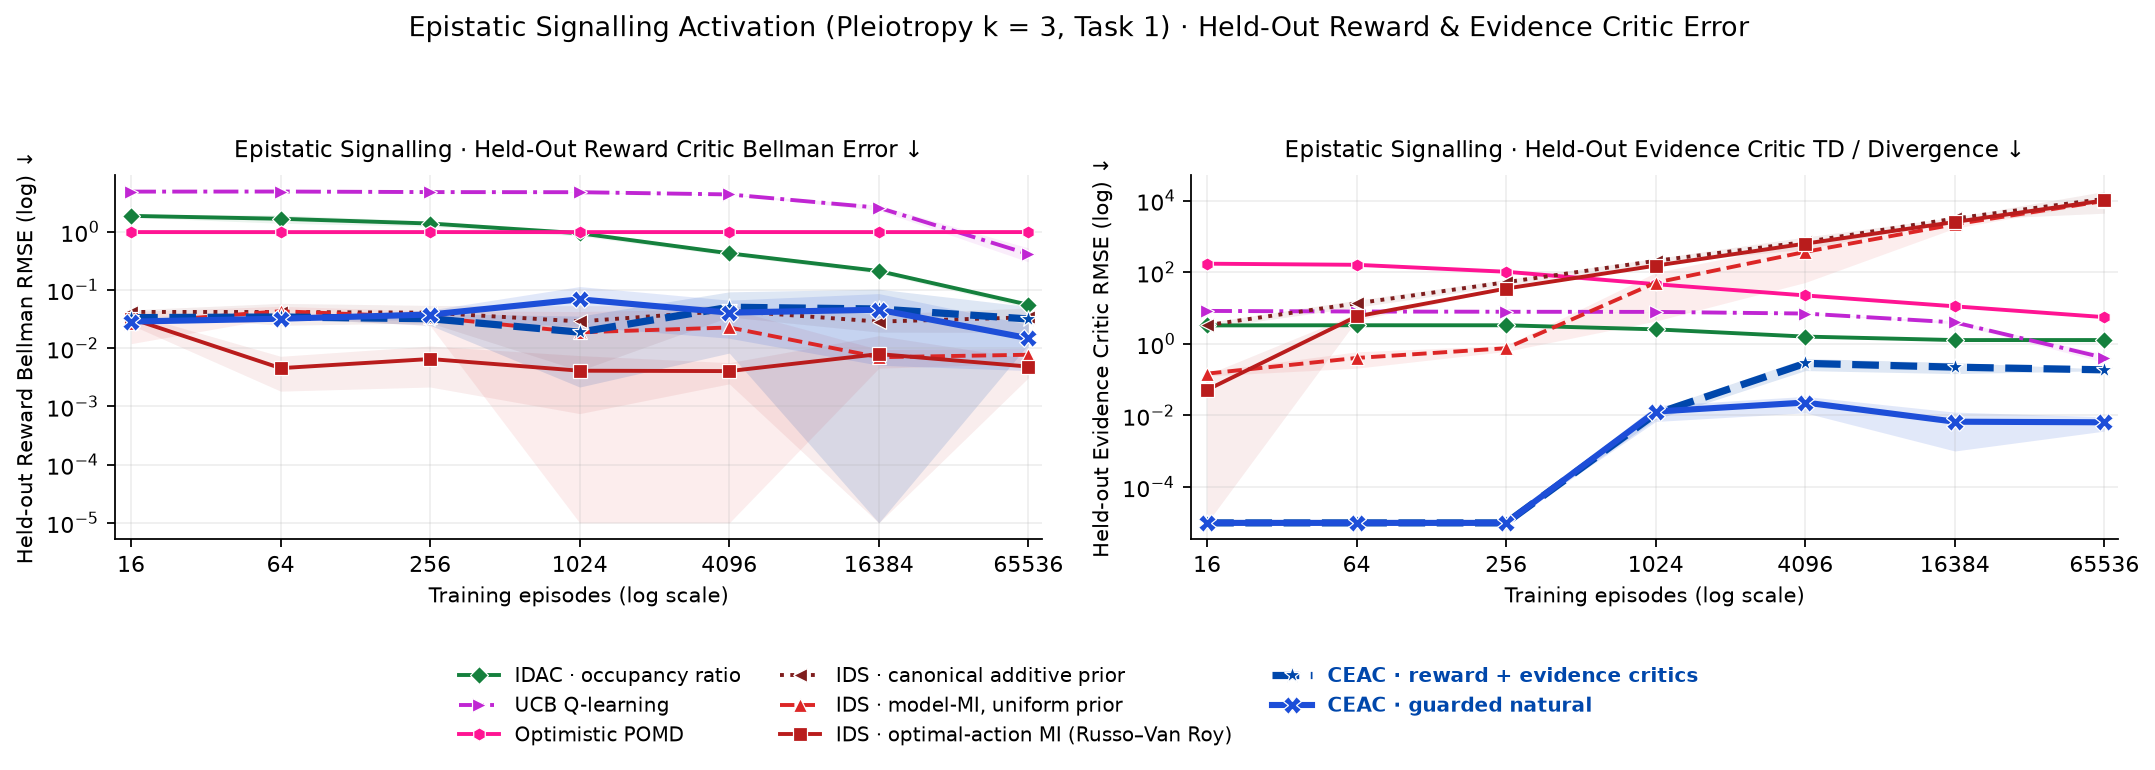

In [3]:
fig = draw_architecture("epistasis")
plt.show()
fig = draw_response(epistasis)
plt.show()
fig = draw_epistasis_overlaid_performance(epistasis, task=1, dose=3)
plt.show()
fig = draw_epistasis_discovery_traces(epistasis, dose=3, task=1)
plt.show()
spec_epi = SUITE_SPECS["epistasis"]
fig = draw_suite_critic_traces(
    epistasis_critic["cells"],
    spec_epi["kinds"],
    target_dose=spec_epi["target_dose"],
    suptitle=spec_epi["traces_title"],
    method_order=spec_epi["methods"],
)
plt.show()


### 2.2 Multi-Step Path-Dependent Signalling Rewiring (`signalling_rewiring`, $H = 3$) — Breaking Optimal-Action IDS

Step-1 `EGFR/MEK` priming ($-0.015$, `0` KL) unlocks $R = 8$ bypass co-targets ($0.92$ vs. $0.10$) amidst $6k$ peripheral mRNA echo clades and $(3^k - 1)$ off-path stress states, breaking **both** `ids_action_tree` and `ids_action_onpath` across $k = 0 \to 3$ while periwinkle `ceac_ranked` stays flat near `~40` regret.


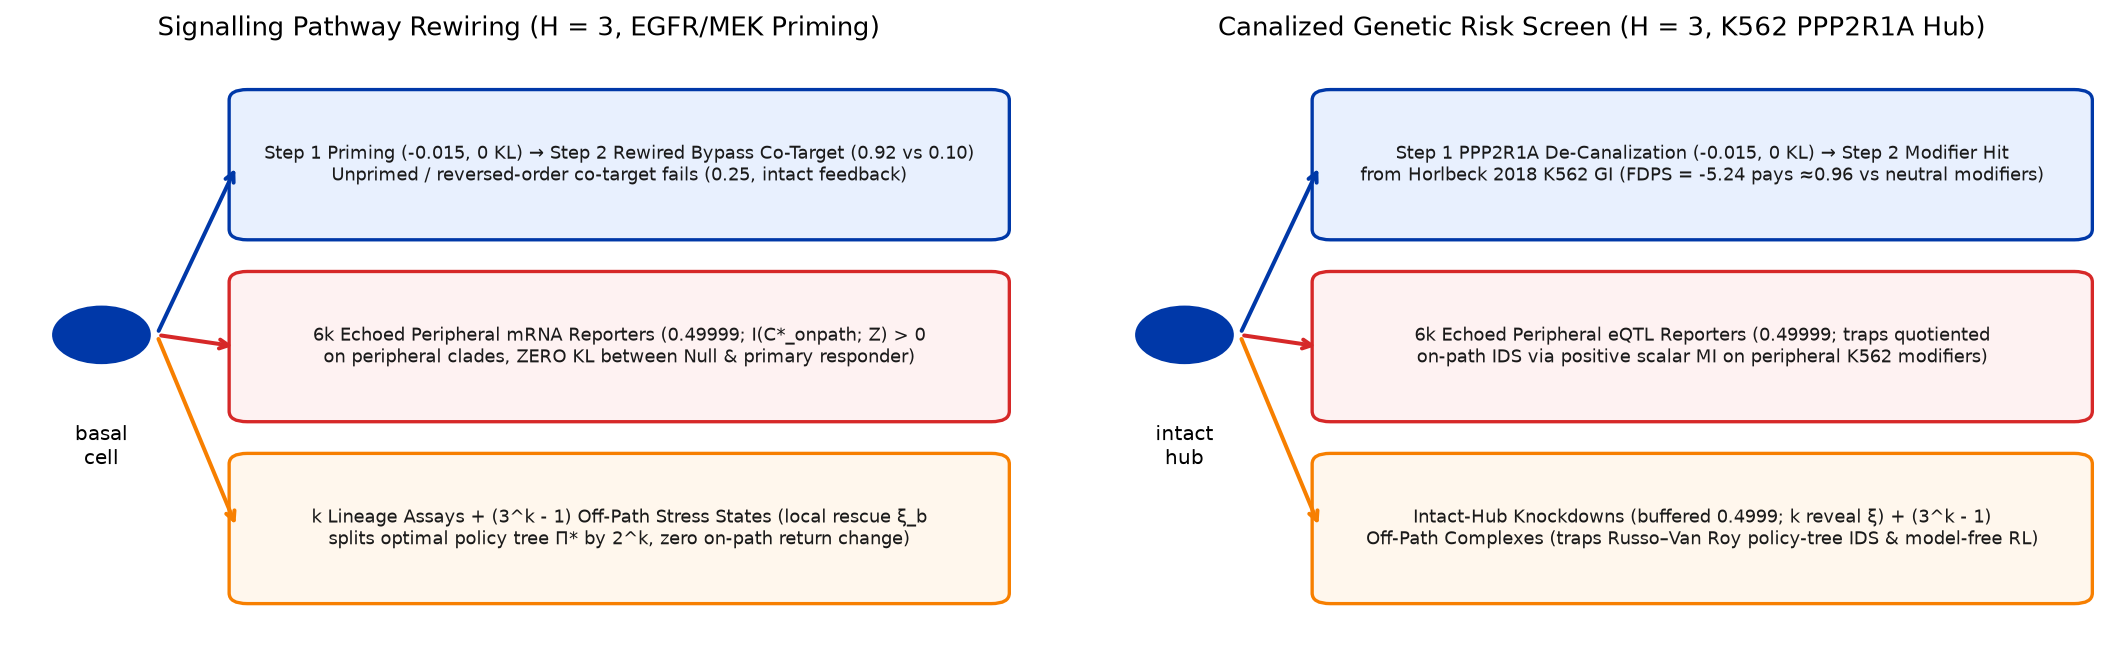

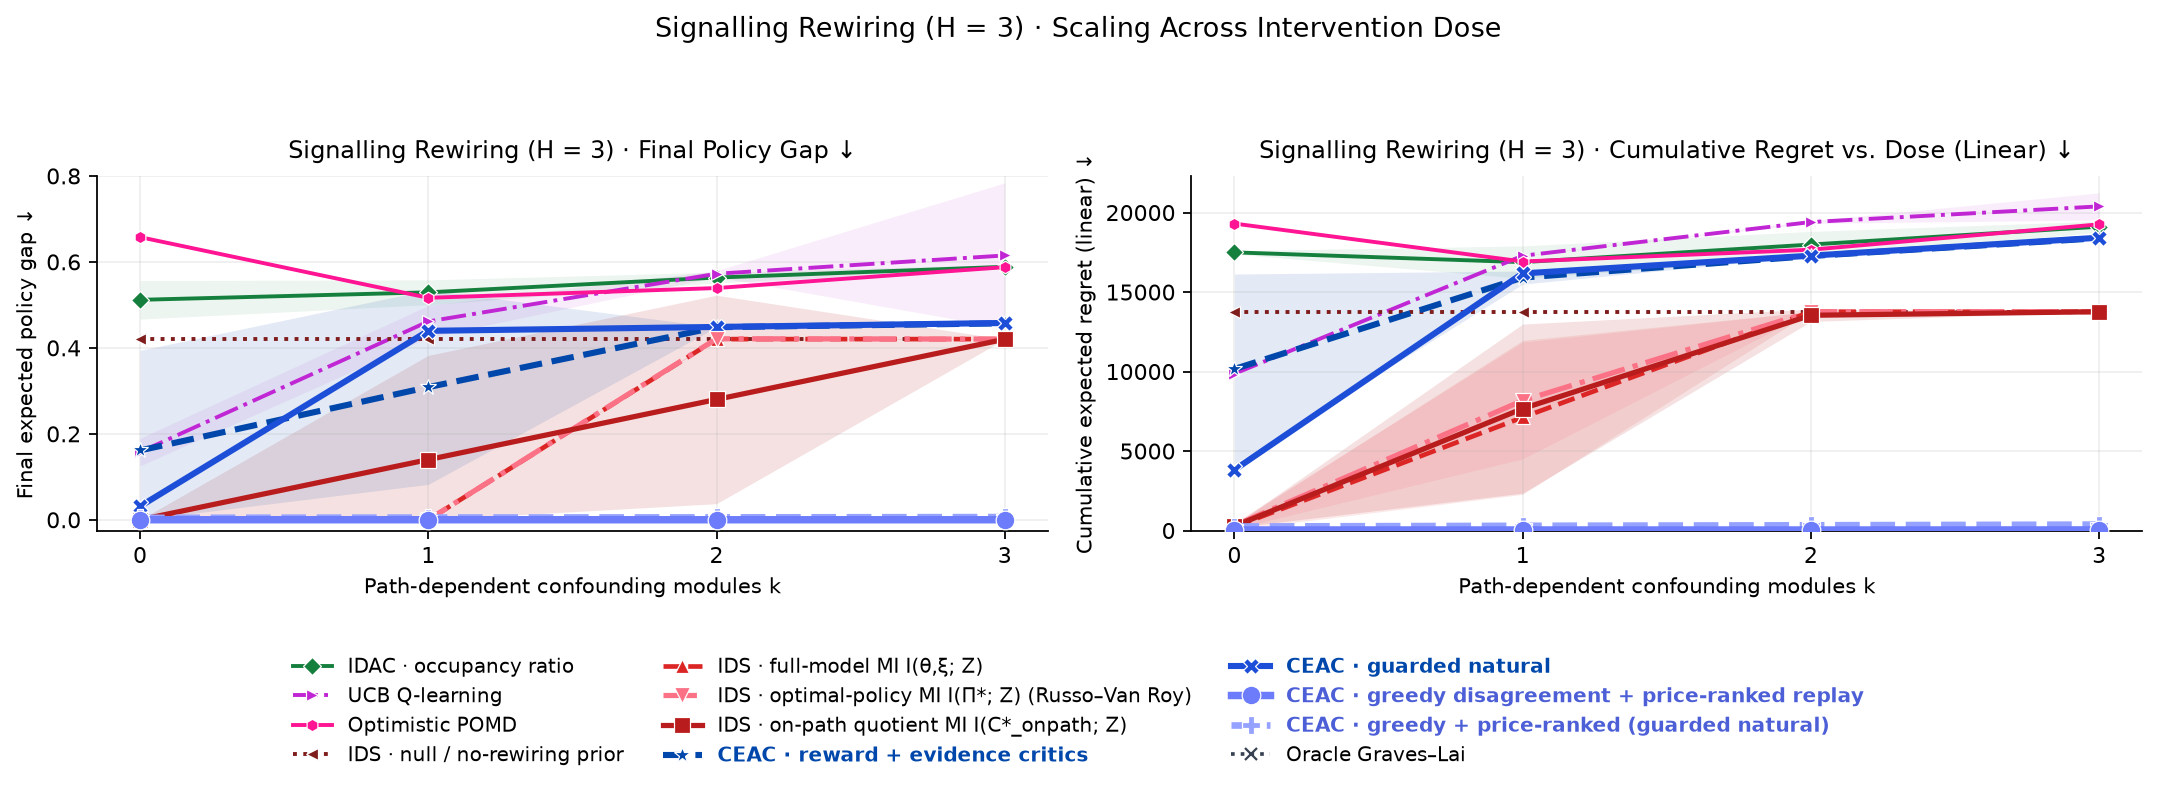

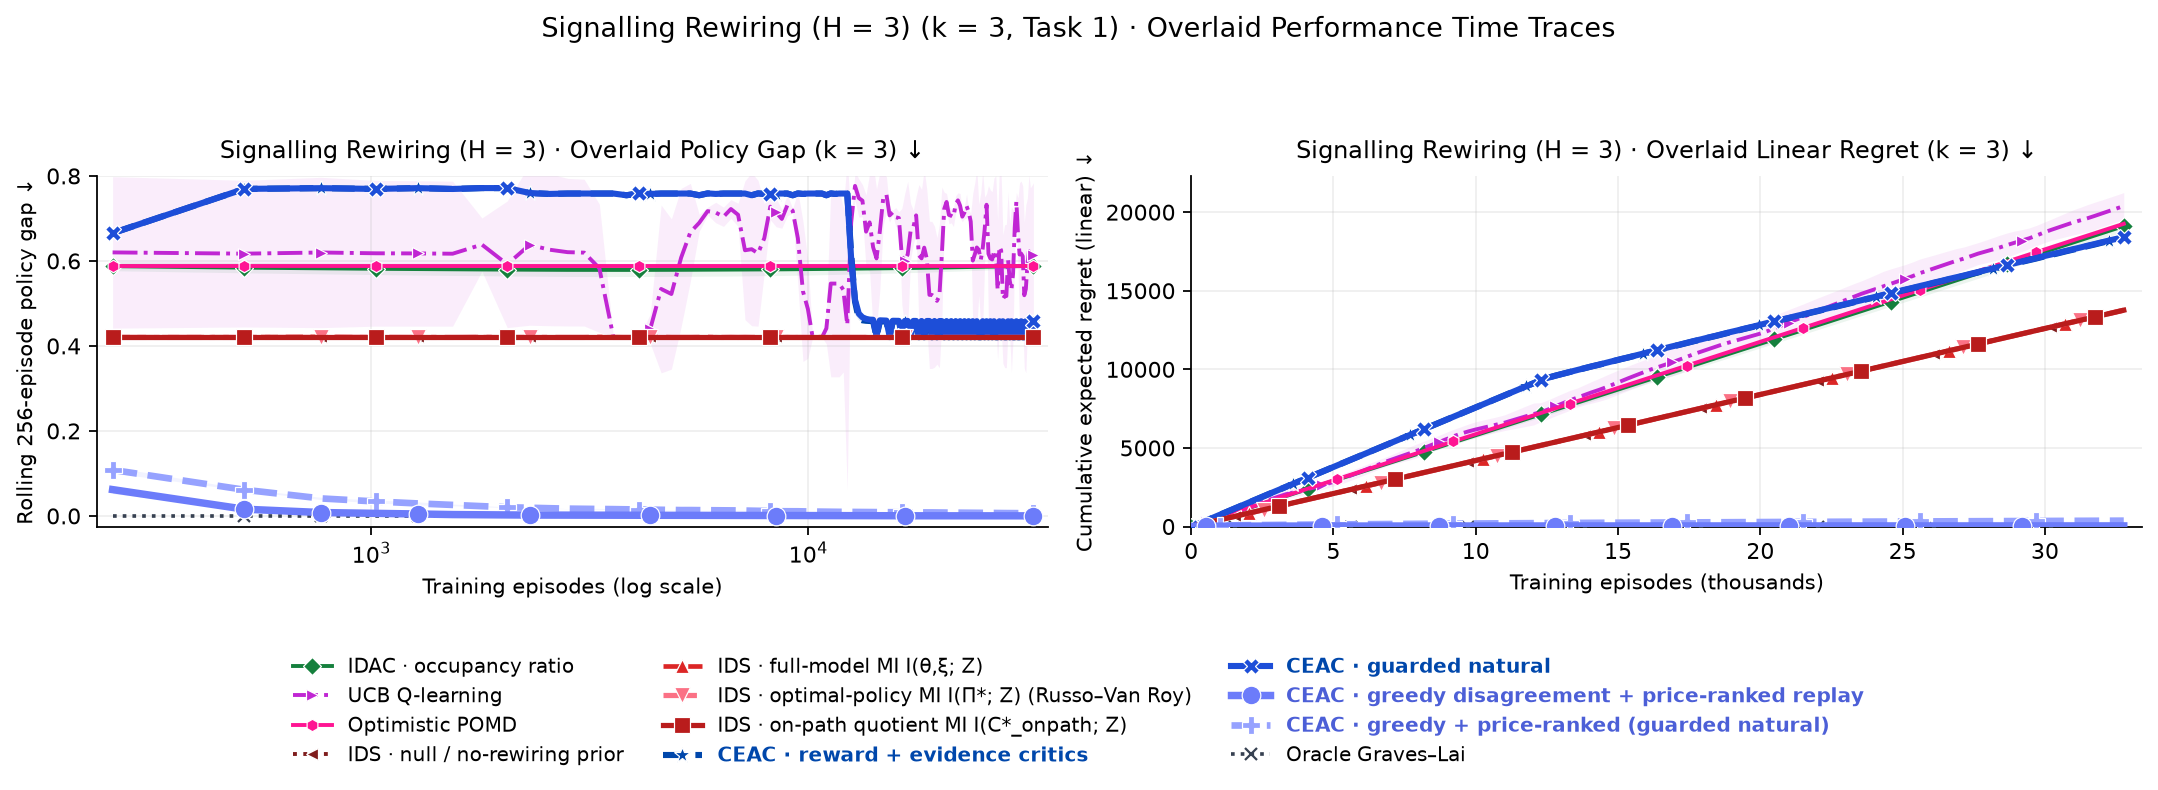

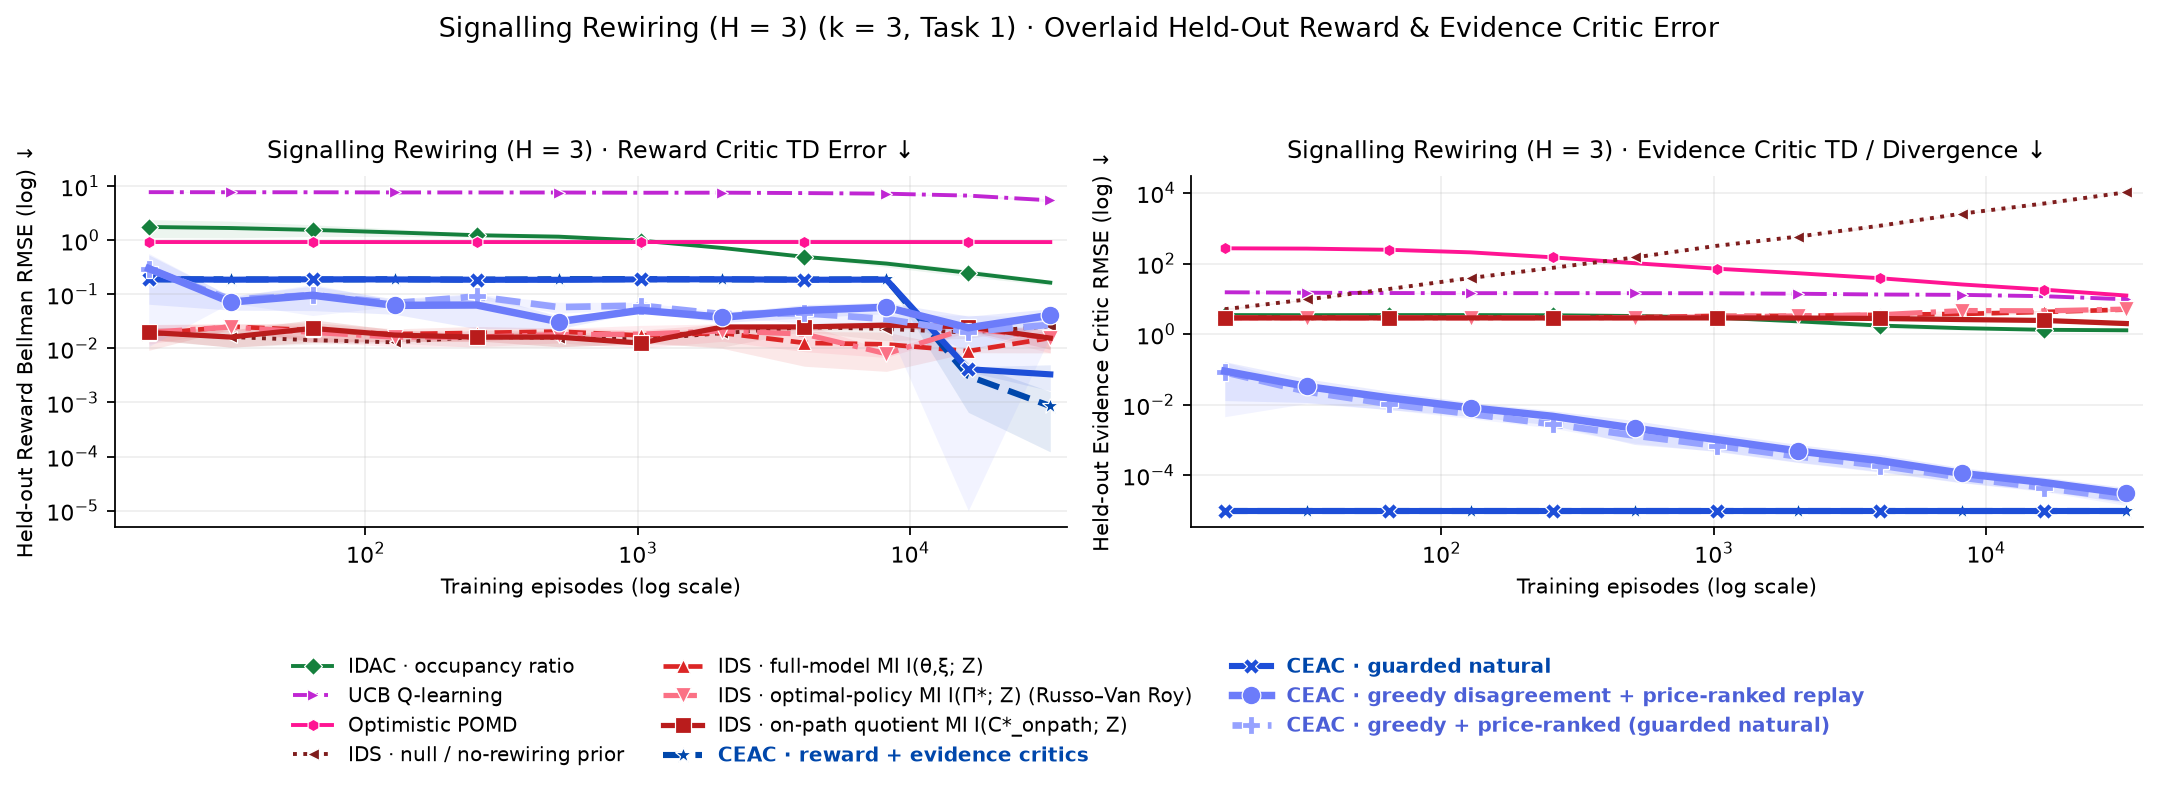

In [4]:
fig = draw_pathdep_architecture()
plt.show()
for plotter in (
    SingleEnvDoseScalingPlot("signalling_rewiring"),
    SingleEnvTimeTracePlot("signalling_rewiring", dose=3),
    SingleEnvCriticBellmanPlot("signalling_rewiring", dose=3),
):
    fig = plotter(bio_pathdep_bundle)
    plt.show()


---
## Part III — Human K562 Genetic Interaction Family (Horlbeck et al., 2018)


### 3.1 Pairwise K562 Interaction Screens (`gi_arrayed` & `gi_multiplexed`) & Greedy Price-Ranked CEAC


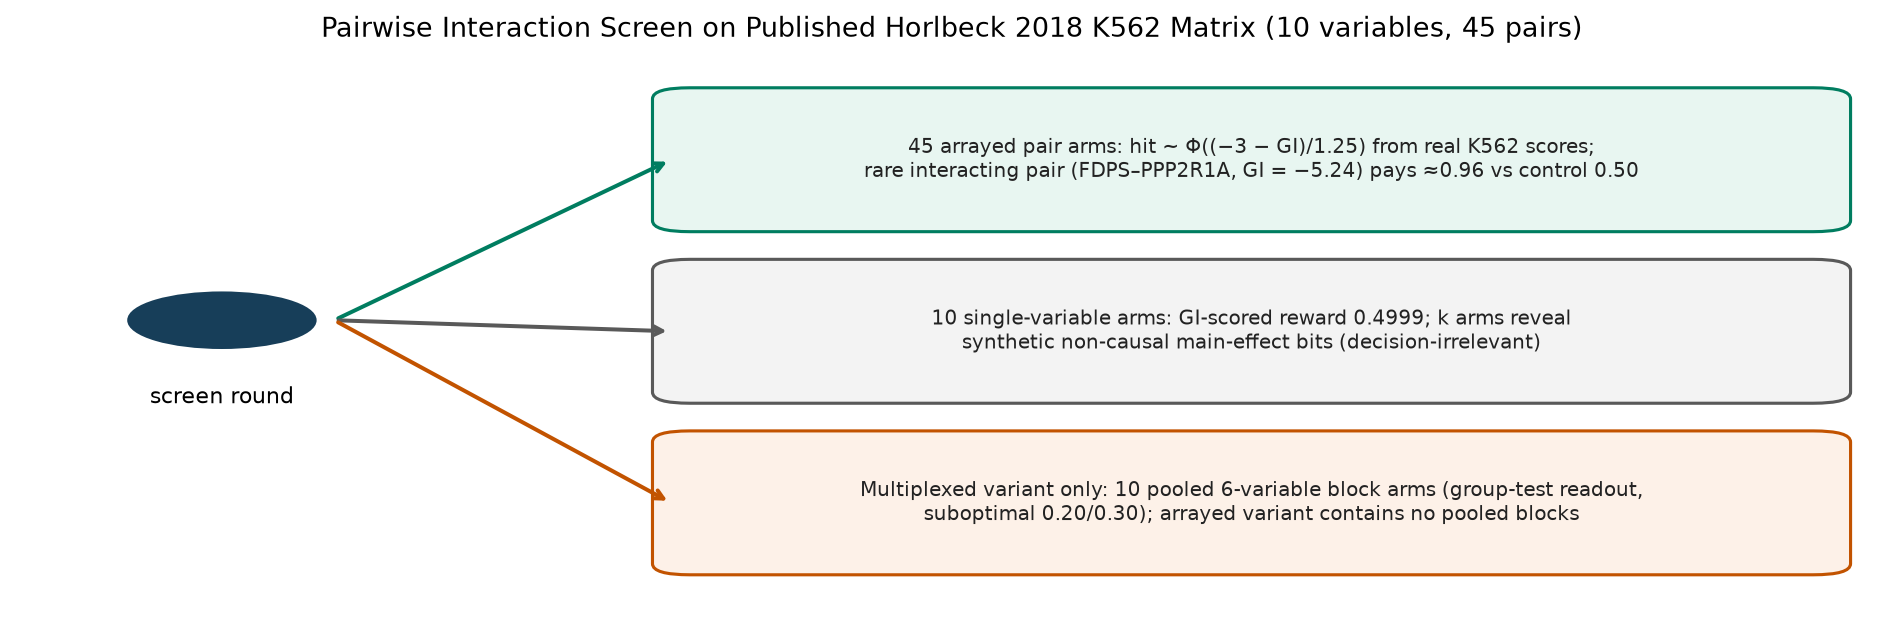

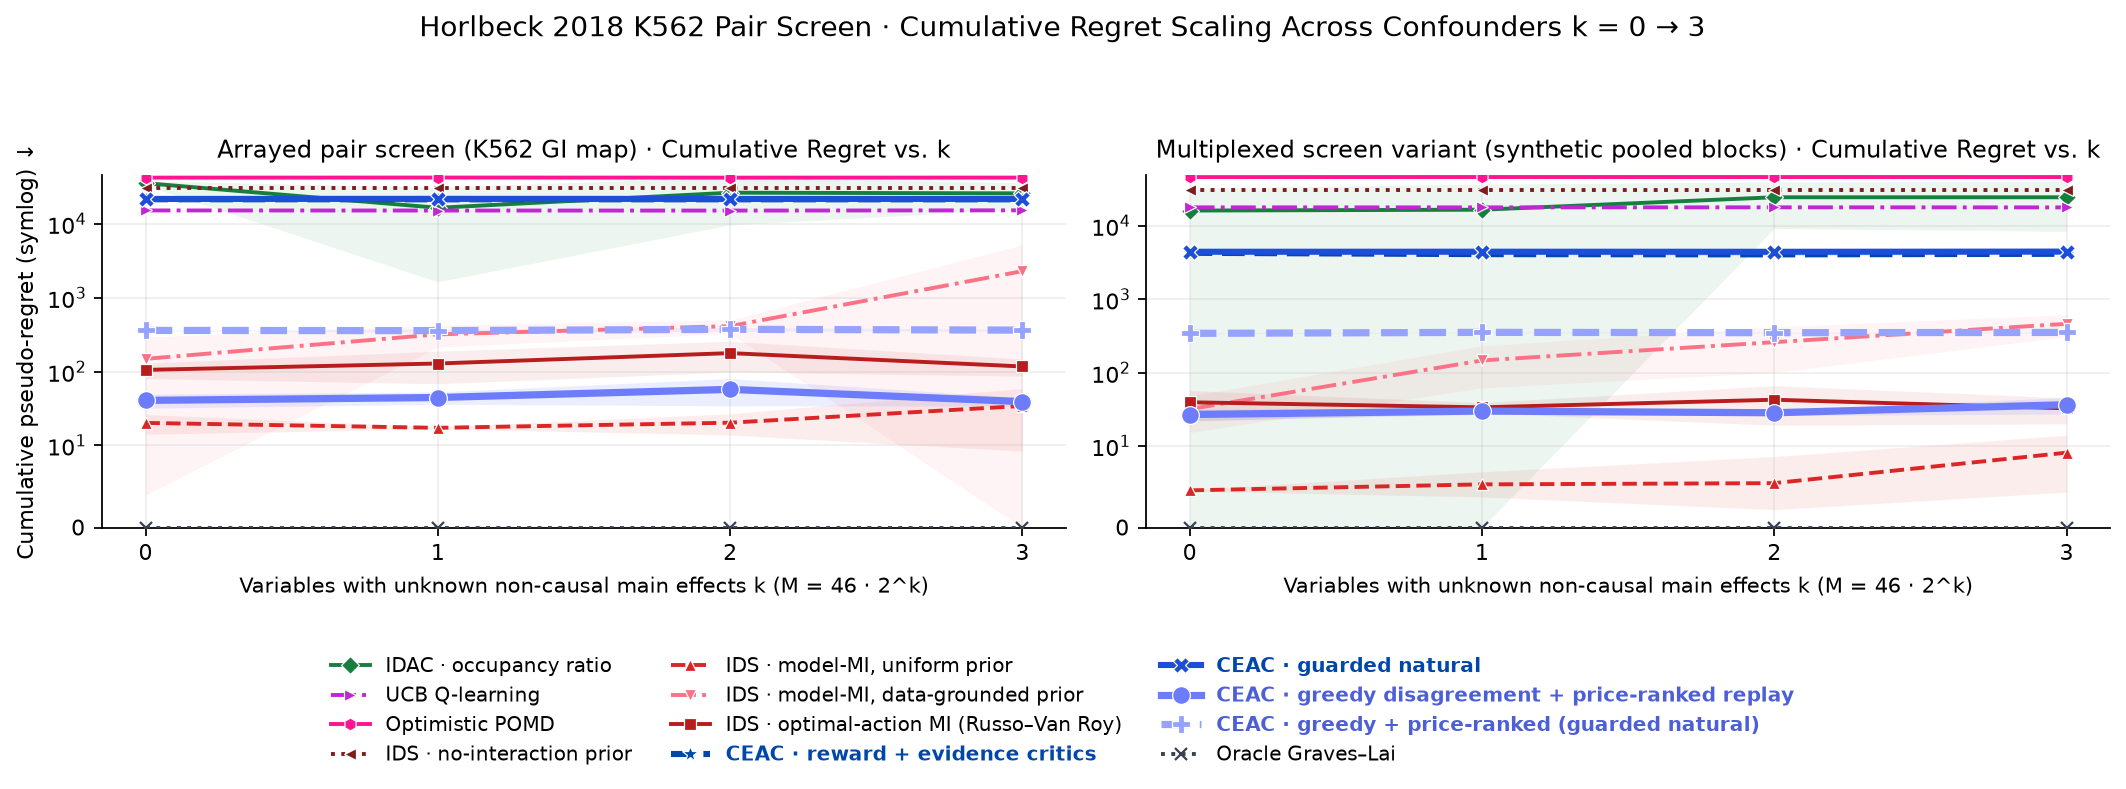

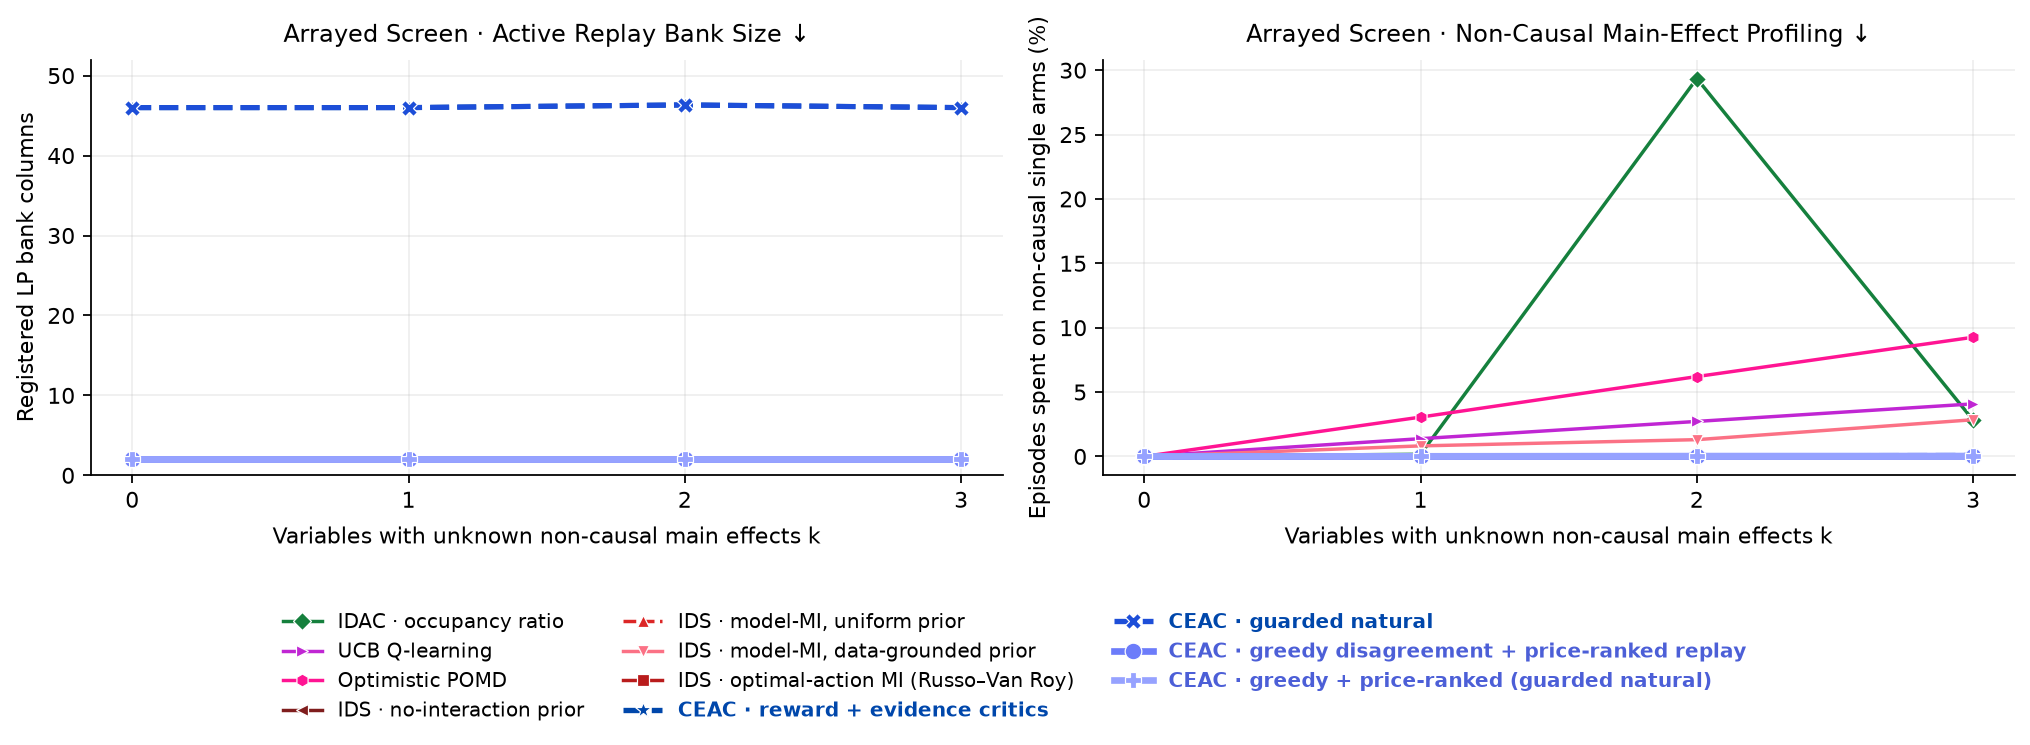

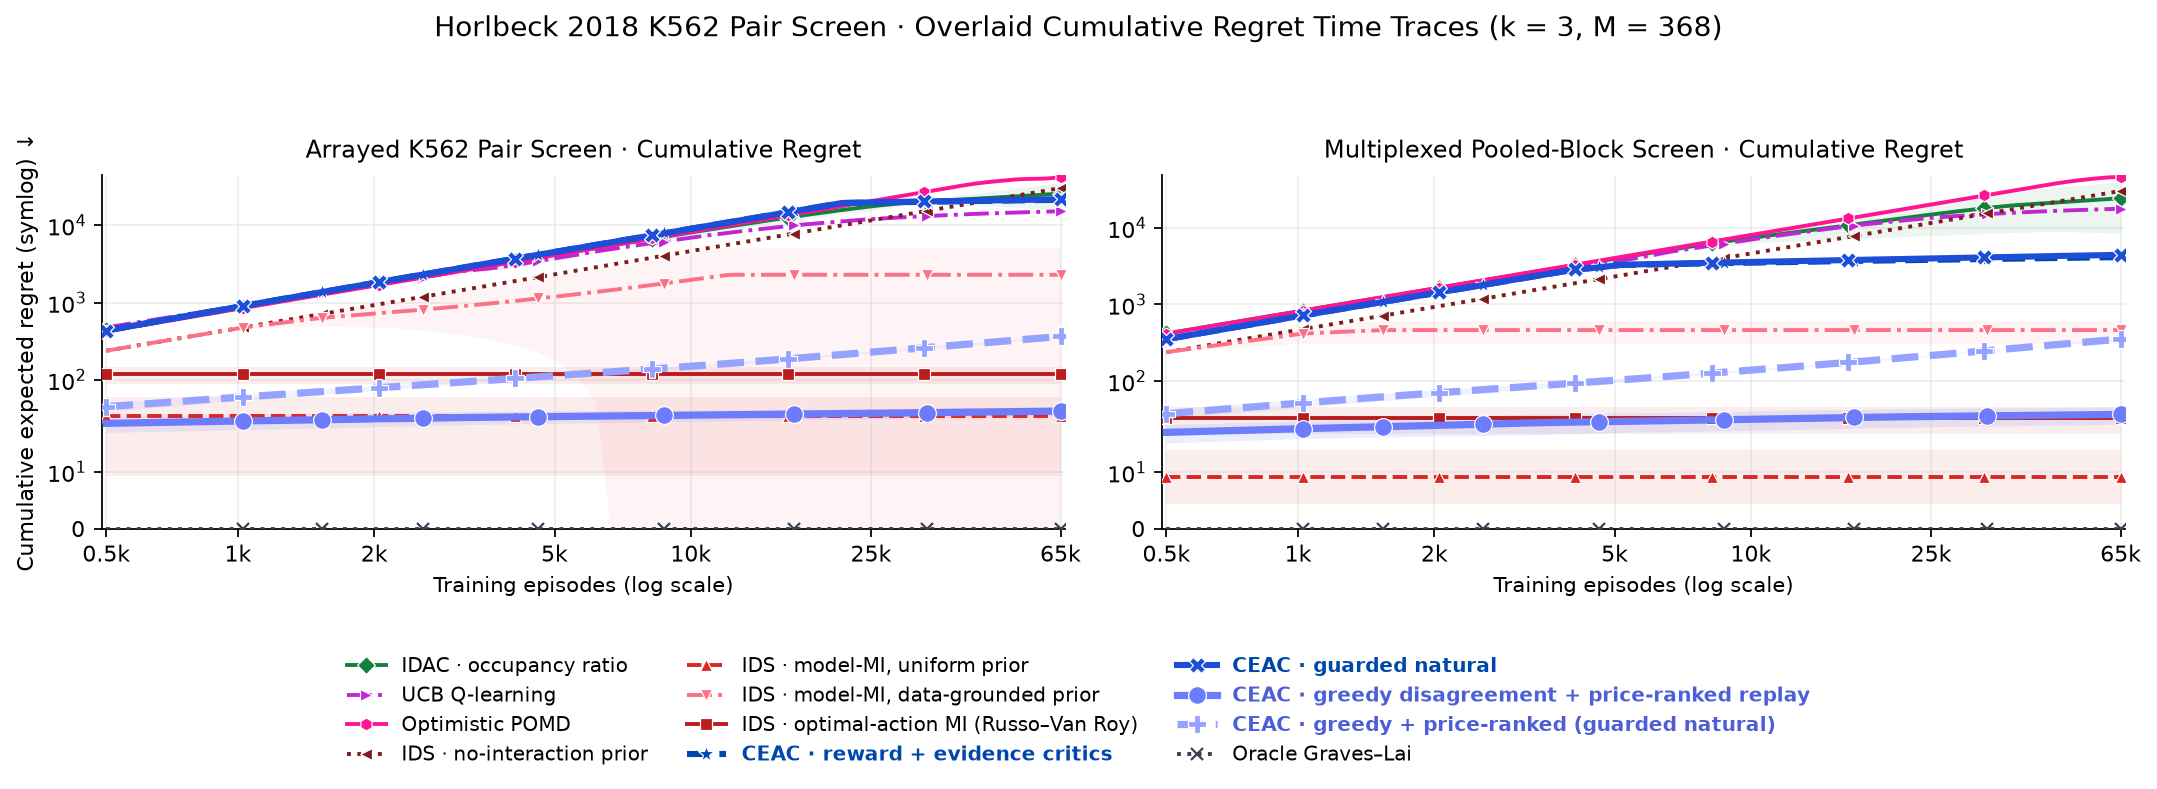

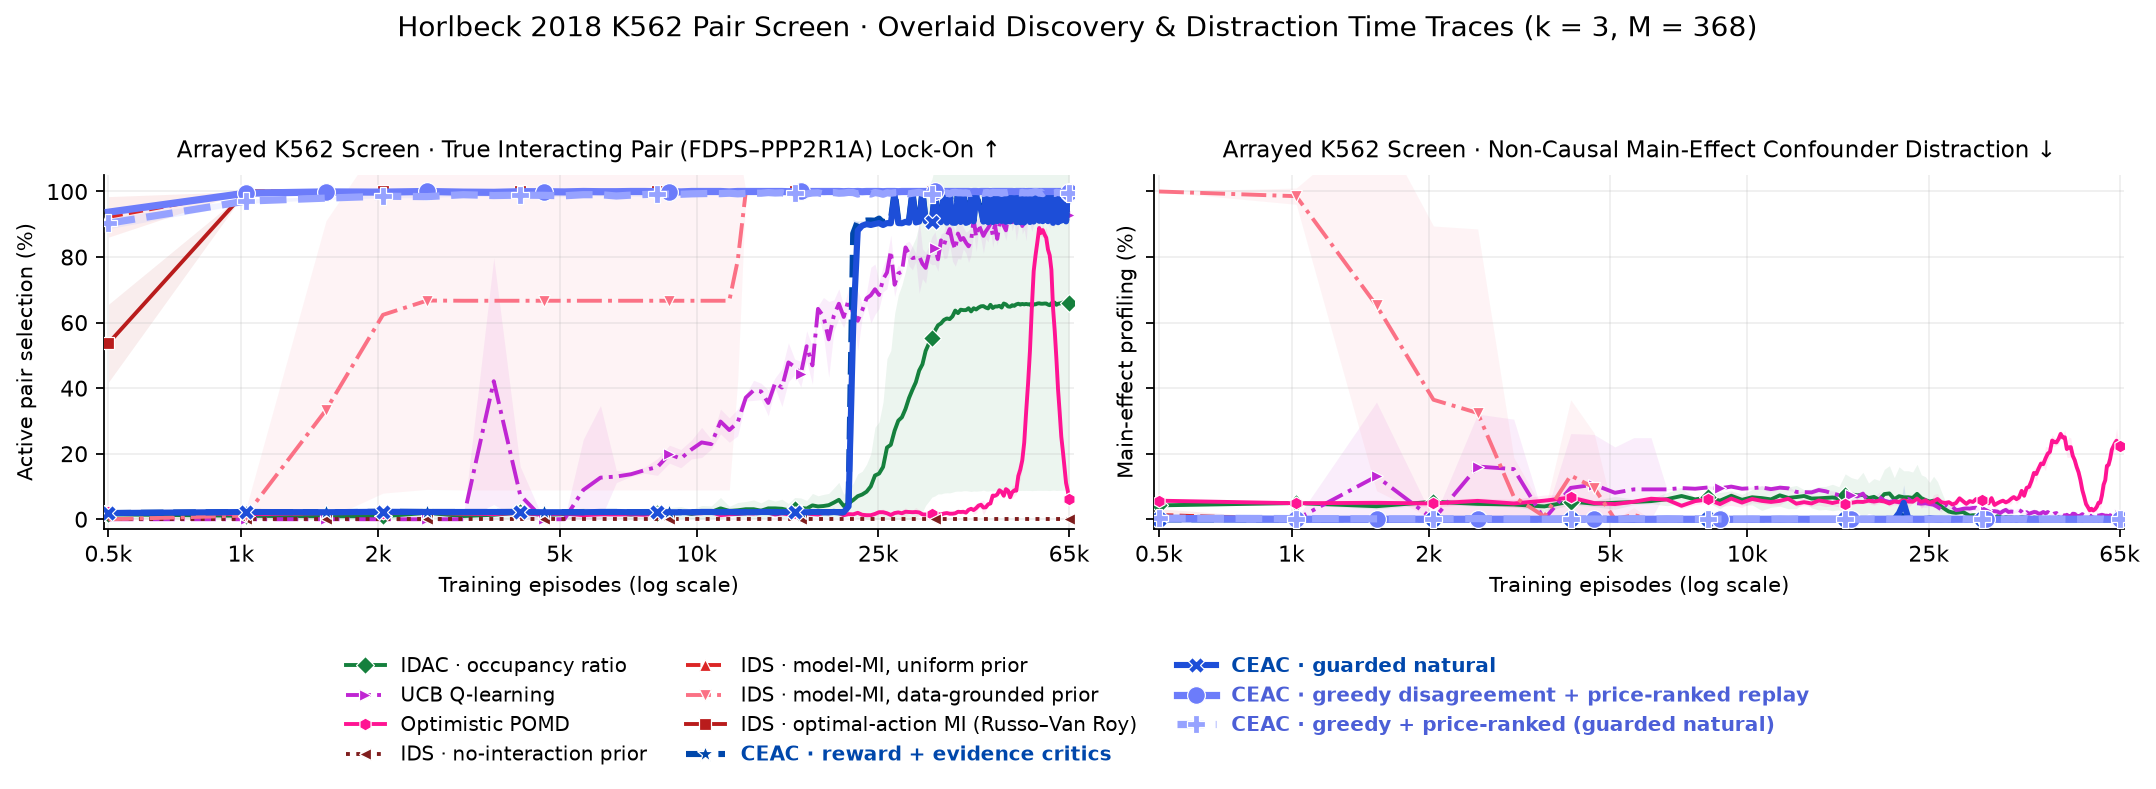

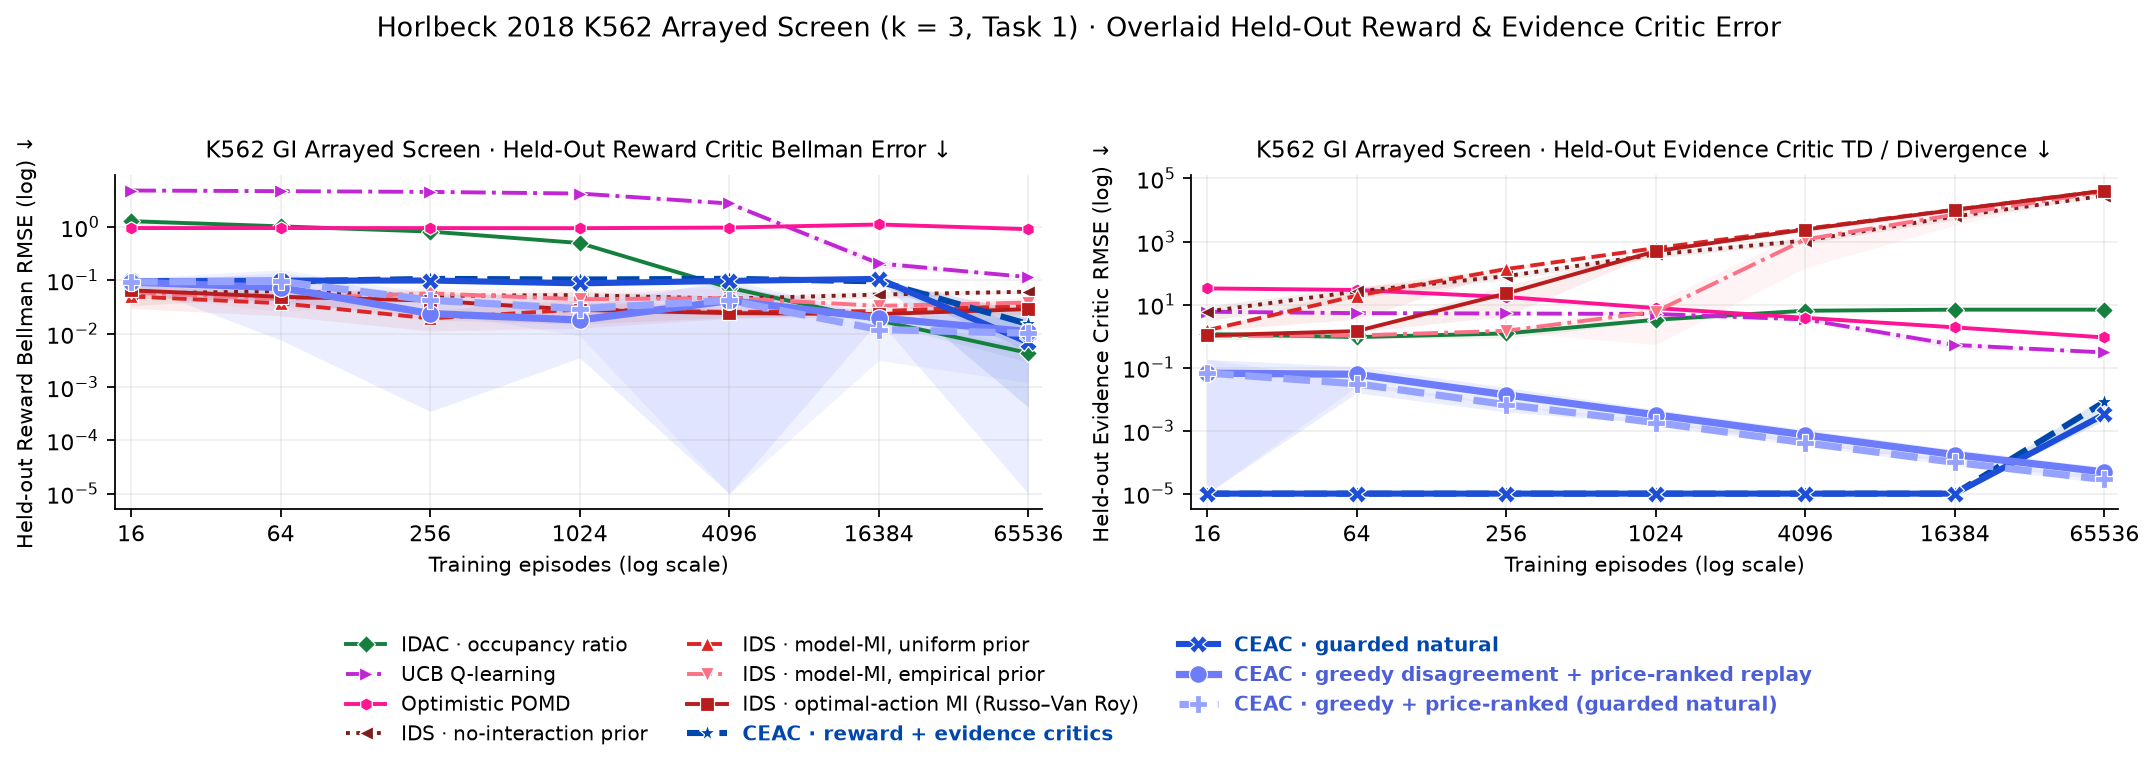

In [5]:
fig = draw_architecture("gi_screen")
plt.show()
fig = draw_gi_ranked_response(gi_ranked["summary_rows"])
plt.show()
fig = draw_gi_ranked_mechanisms(gi_ranked["summary_rows"])
plt.show()
fig = draw_gi_overlaid_performance(gi_ranked, dose=3, metric="cumulative_regret")
plt.show()
fig = draw_gi_discovery_traces(gi_ranked, dose=3)
plt.show()
spec_gi = SUITE_SPECS["gi_ranked"]
fig = draw_suite_critic_traces(
    gi_critic["cells"],
    [("gi_arrayed", "K562 GI Arrayed Screen")],
    target_dose=spec_gi["target_dose"],
    suptitle="Horlbeck 2018 K562 Arrayed Screen (k = 3, Task 1) · Overlaid Held-Out Reward & Evidence Critic Error",
    method_order=spec_gi["methods"],
    ranked_ceac_present=True,
)
plt.show()


### 3.2 Multi-Step Canalized K562 Genetic Risk Screen (`canalized_gi`, `PPP2R1A` Hub, $H = 3$) — Breaking Optimal-Action IDS

Step-1 `PPP2R1A` de-canalization ($-0.015$, `0` KL) exposes `FDPS` synthetic lethality ($\text{GI} = -5.24$, hit $\approx 0.96$) amidst $6k$ eQTL-echoed modifiers and $(3^k - 1)$ off-path complexes, breaking both `ids_action_tree` and `ids_action_onpath` while periwinkle `ceac_ranked` stays flat near `~37` regret.


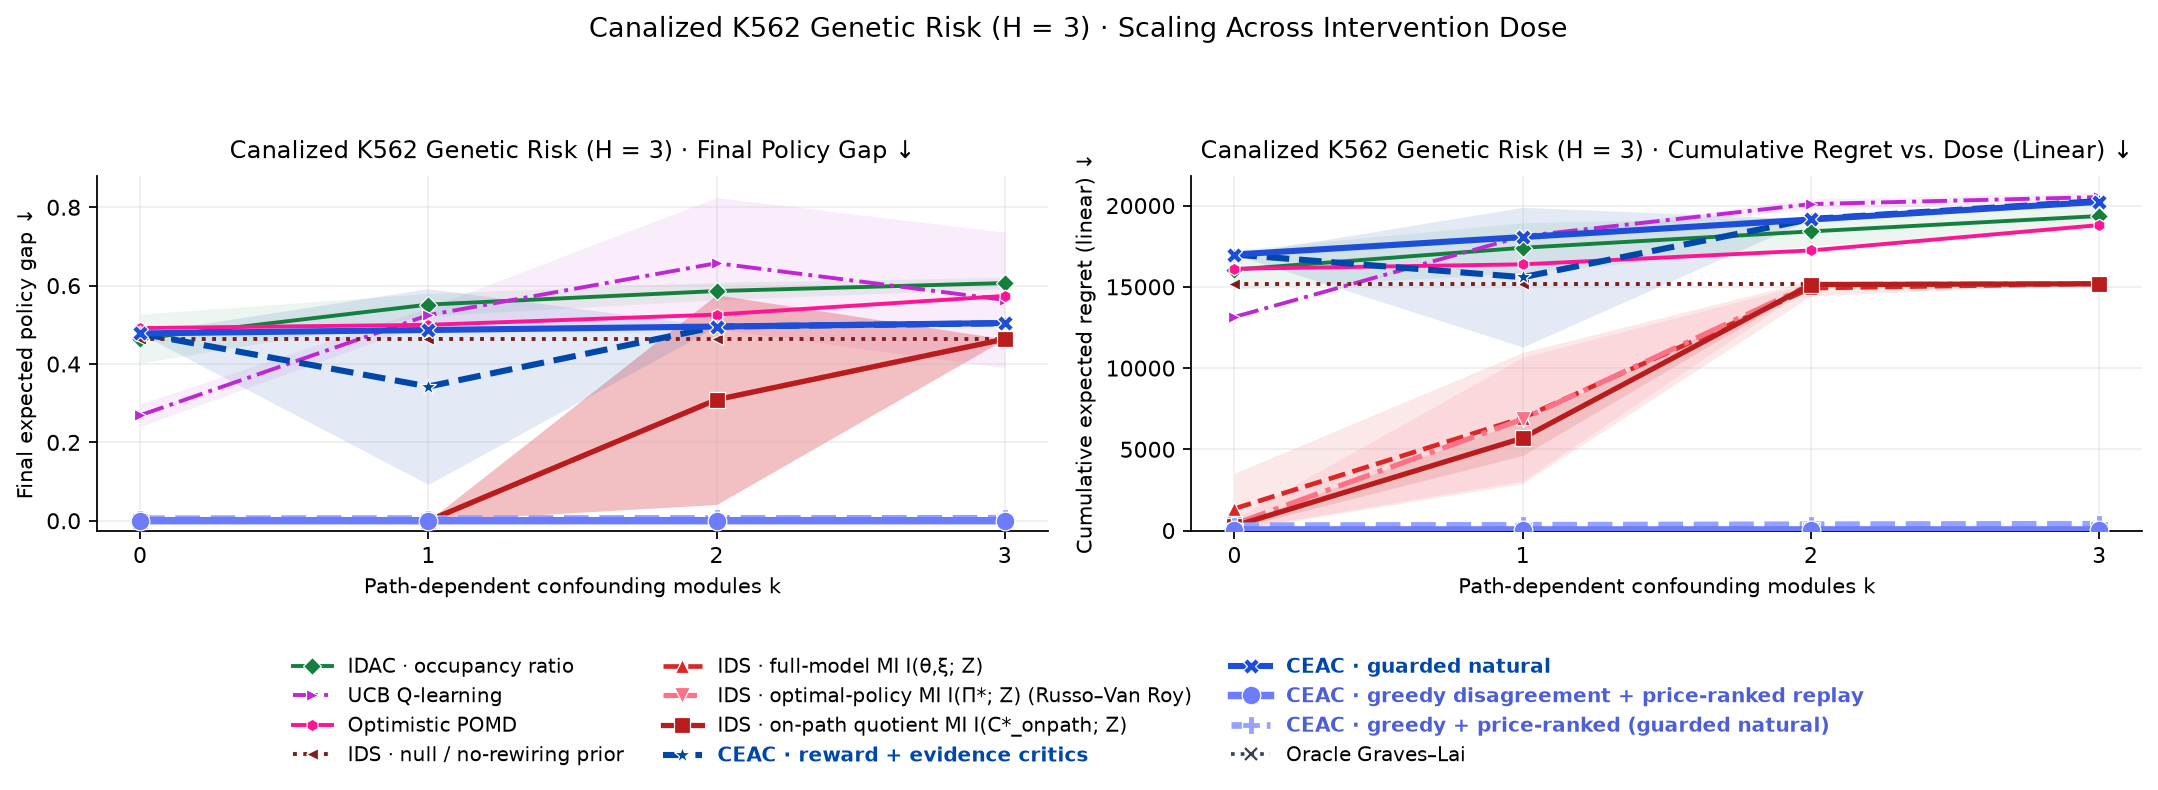

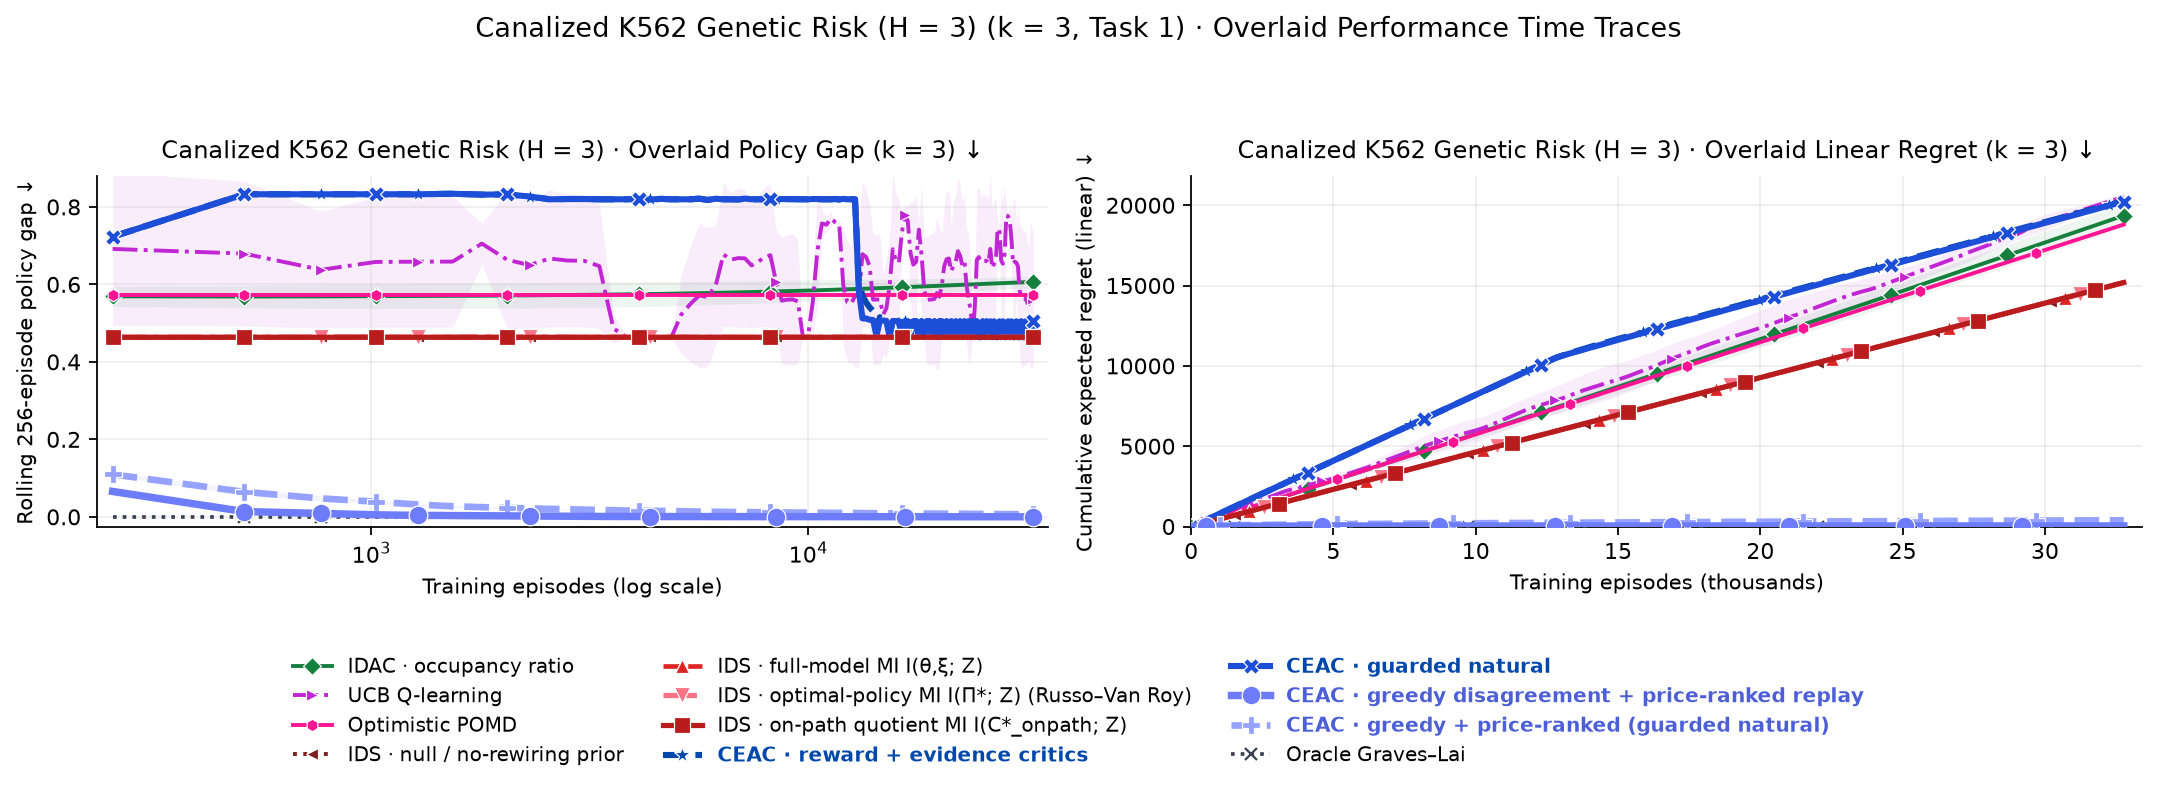

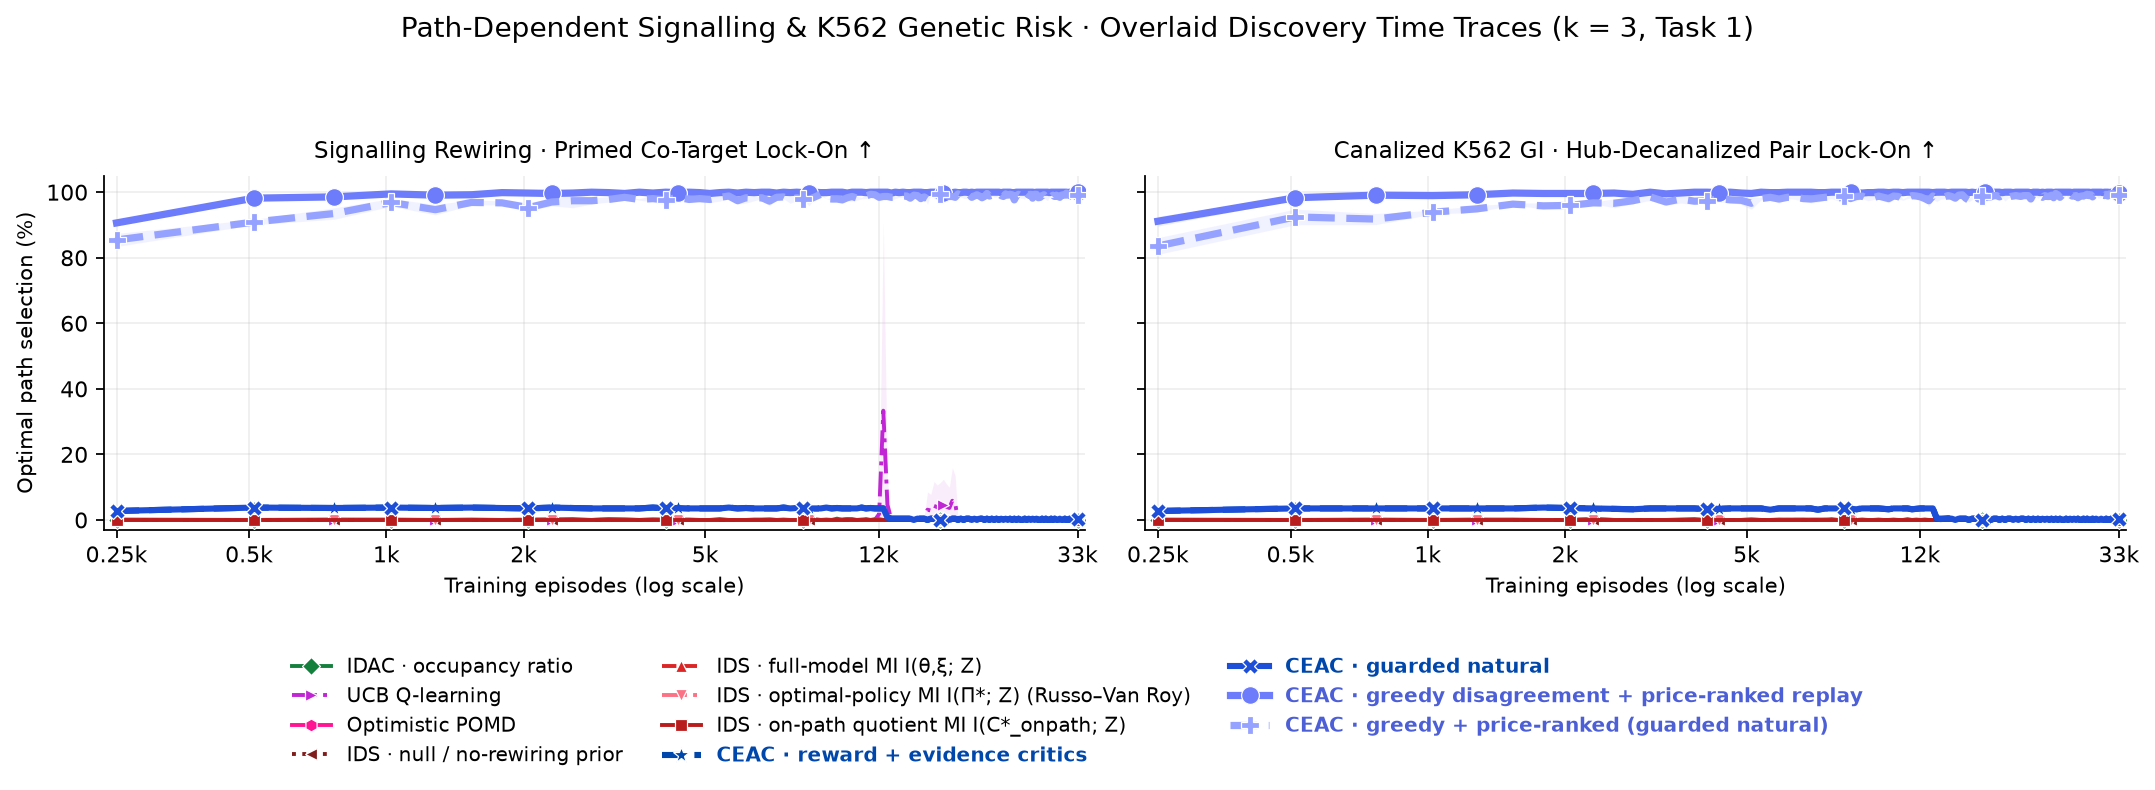

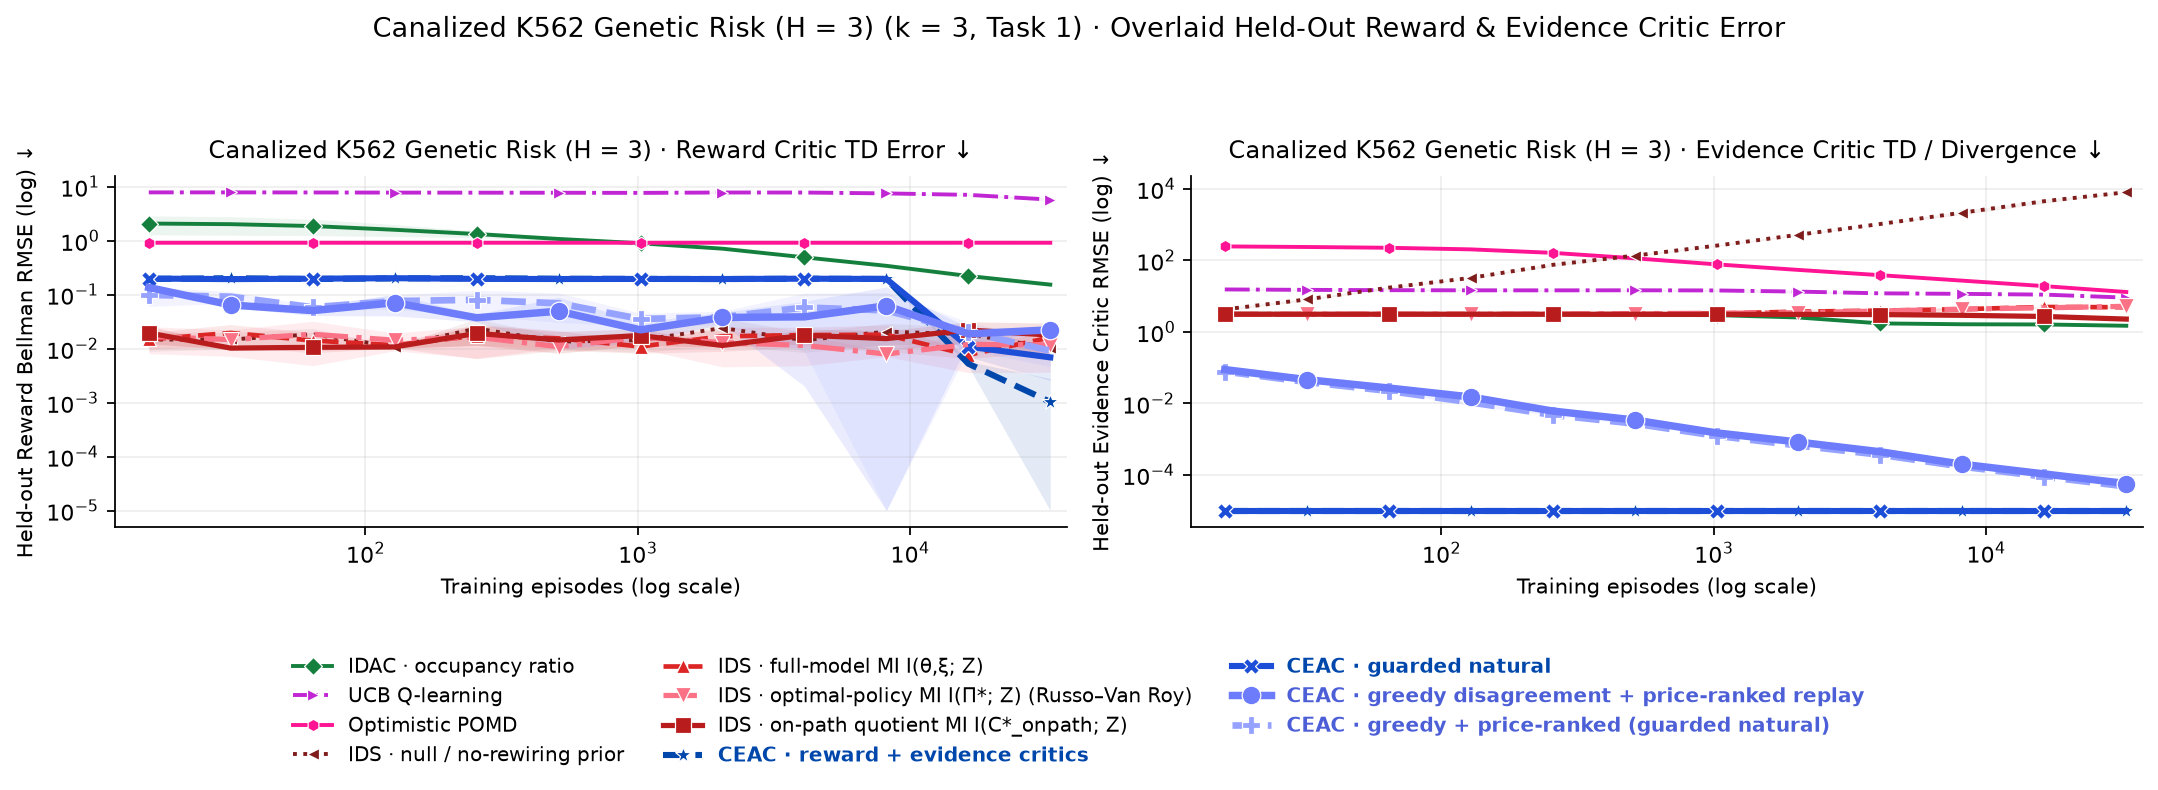

In [6]:
for plotter in (
    SingleEnvDoseScalingPlot("canalized_gi", gap_ylim=(-0.025, 0.88)),
    SingleEnvTimeTracePlot("canalized_gi", dose=3, gap_ylim=(-0.025, 0.88)),
):
    fig = plotter(bio_pathdep_bundle)
    plt.show()
fig = draw_pathdep_discovery_traces(pathdep_raw, dose=3)
plt.show()
fig = SingleEnvCriticBellmanPlot("canalized_gi", dose=3)(bio_pathdep_bundle)
plt.show()


---
## Part IV — Consolidated `StudyBundle` Summary Tables & Unified CLI Entrypoints


In [7]:
print("=== Multi-Step Path-Dependent Signalling & K562 GI Summary (Task 1, k = 0 -> 3) ===")
print(DoseTransitionMarkdownTable()(bio_pathdep_bundle))
print("=== Seed-Paired Regret Savings at k = 3 (`ceac_ranked`) ===")
print(PairedAdvantageMarkdownTable("ceac_ranked")(bio_pathdep_bundle))

CLI_COMMANDS = {
    "architecture_tests": ".venv/bin/python -m unittest discover -s tests/architecture -v",
    "check_boundaries": ".venv/bin/python -m ceac_bench.cli check-boundaries",
    "run_bio_pathdep_v2": ".venv/bin/python -m ceac_bench.cli run bio_pathdep --output runs/bio_pathdep_v2 --workers 4",
    "rebuild_this_notebook": ".venv/bin/python scripts/render_pathologies_notebook.py --execute",
}
for name, cmd in CLI_COMMANDS.items():
    print(f"[{name}]  {cmd}")


=== Multi-Step Path-Dependent Signalling & K562 GI Summary (Task 1, k = 0 -> 3) ===
| Benchmark | Algorithm | Final Gap (min → max) | Regret (min → max) | Evidence Critic RMSE (max) |
|---|---|---:|---:|---:|
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | IDAC · occupancy ratio | 0.4649 → 0.6066 | 16,060.0 → 19,356.8 | 1.4778 |
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | UCB Q-learning | 0.2690 → 0.5635 | 13,144.8 → 20,523.0 | 9.0508 |
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | Optimistic POMD | 0.4917 → 0.5738 | 16,111.1 → 18,800.8 | 12.9965 |
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | IDS · null / no-rewiring prior | 0.4635 → 0.4635 | 15,188.5 → 15,188.5 | 8,013.5050 |
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | IDS · full-model MI I(θ,ξ; Z) | 0.0000 → 0.4635 | 1,344.2 → 15,190.8 | 4.8752 |
| Canalized Genetic Risk Screen (K562 PPP2R1A Hub, H = 3) | IDS · optimal-policy MI I(Π*; Z) (Russo–Van Roy) | 0.0000